In [114]:
# ===================================
# LSTM Autoencoder
# UNSW-NB15
# ===================================


# Librairies générales

import numpy as np
import pandas as pd
import os



# Visualisation

import matplotlib.pyplot as plt
import seaborn as sns



# Prétraitement

from sklearn.preprocessing import MinMaxScaler, LabelEncoder



# Séparation données

from sklearn.model_selection import train_test_split



# Evaluation

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    auc
)



# TensorFlow / Keras

import tensorflow as tf


from tensorflow.keras.models import Model


from tensorflow.keras.layers import (
    Input,
    LSTM,
    Dense,
    RepeatVector,
    TimeDistributed
)


from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint
)



# Diagramme architecture

from tensorflow.keras.utils import plot_model



# Reproductibilité

np.random.seed(42)

tf.random.set_seed(42)



# ===================================
# Création dossiers sauvegarde
# ===================================


os.makedirs(
    "figures",
    exist_ok=True
)


os.makedirs(
    "models",
    exist_ok=True
)


os.makedirs(
    "results",
    exist_ok=True
)

In [2]:
dataset_path = "UNSW-NB15_1.csv"
df = pd.read_csv(dataset_path, header = None,low_memory=False)

In [3]:
columns = [
    'srcip','sport','dstip','dsport','proto','state',
    'dur','sbytes','dbytes','sttl','dttl','sloss','dloss',
    'service','Sload','Dload','Spkts','Dpkts',
    'swin','dwin','stcpb','dtcpb','smeansz','dmeansz',
    'trans_depth','res_bdy_len','Sjit','Djit',
    'Stime','Ltime','Sintpkt','Dintpkt',
    'tcprtt','synack','ackdat','is_sm_ips_ports',
    'ct_state_ttl','ct_flw_http_mthd','is_ftp_login',
    'ct_ftp_cmd','ct_srv_src','ct_srv_dst',
    'ct_dst_ltm','ct_src_ltm',
    'ct_src_dport_ltm','ct_dst_sport_ltm',
    'ct_dst_src_ltm','attack_cat','label'
]
df.columns = columns

In [4]:
# ===================================
# Valeurs manquantes
# ===================================


missing_values = df.isnull().sum()

missing_values[missing_values > 0]

attack_cat    677786
dtype: int64

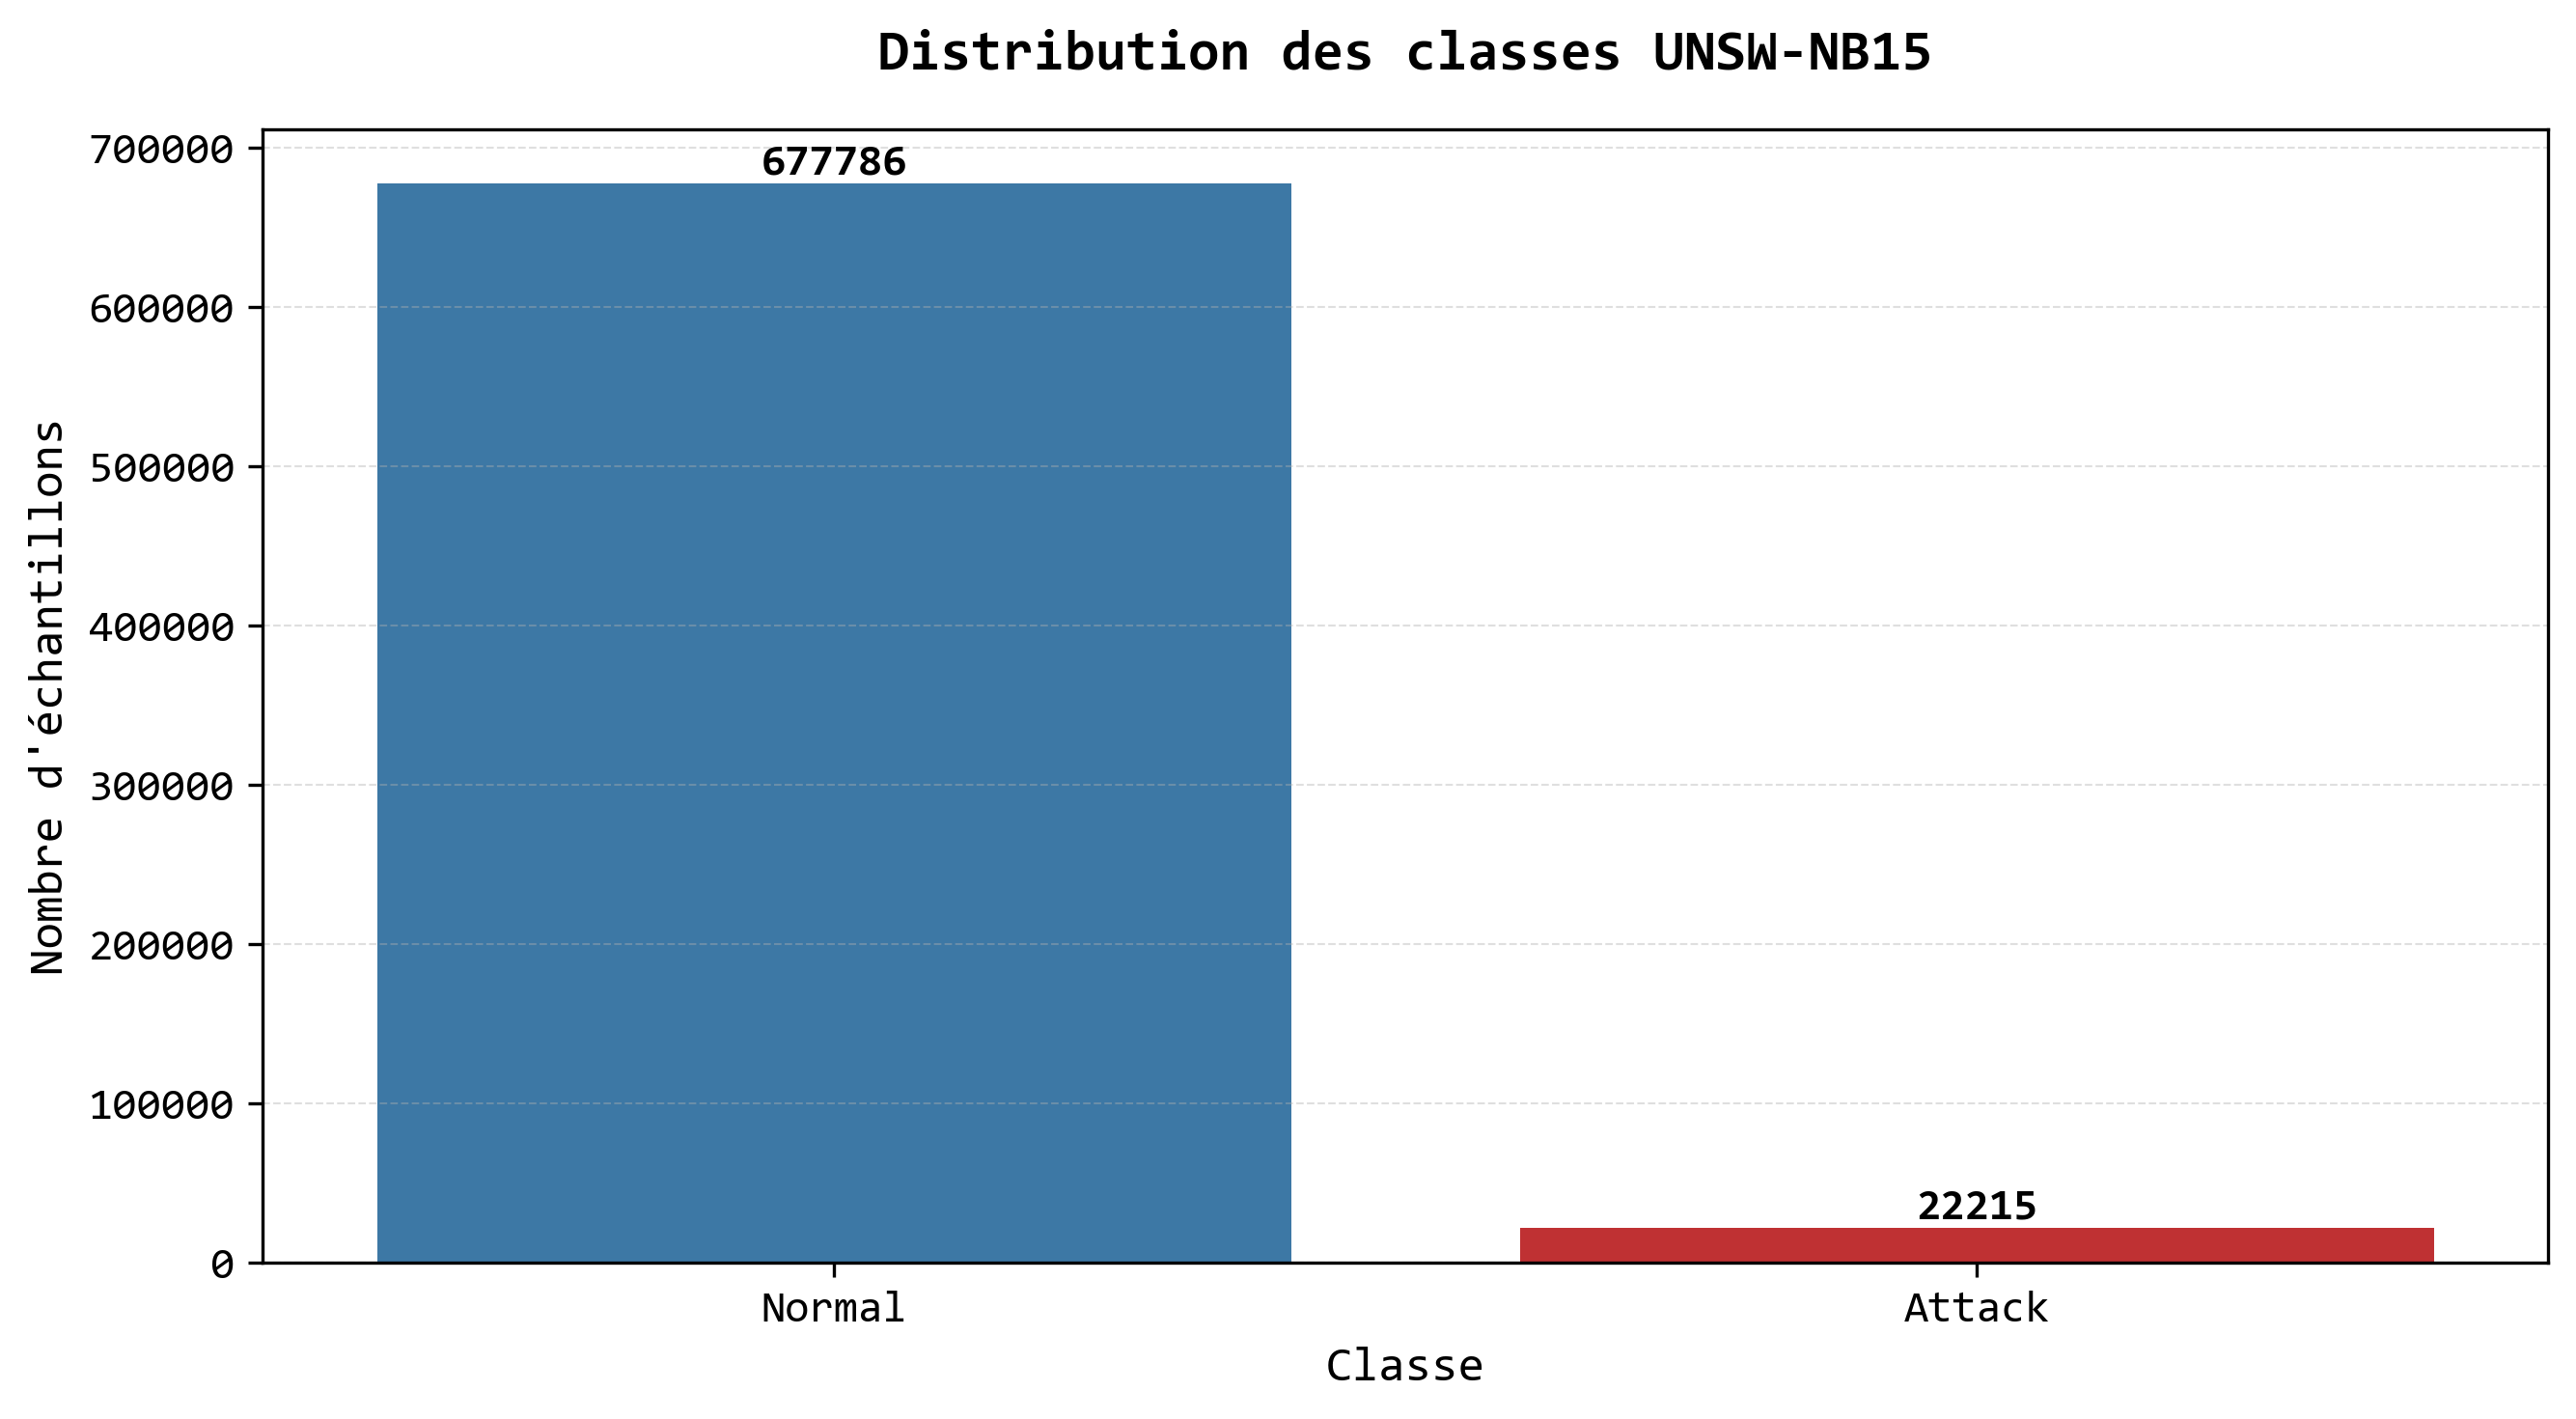

In [113]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import rcParams


# ==========================================
# Police globale Consolas
# ==========================================

rcParams['font.family'] = 'Consolas'


# ==========================================
# Distribution Normal / Attack
# ==========================================

plt.figure(
   figsize=(9,5),
    dpi=300
)



# ==========================================
# Diagramme des classes corrigé Seaborn
# ==========================================

ax = sns.countplot(
    data=df,
    x="label",
    hue="label",
    palette={
        0: "#2C7BB6",   # Normal
        1: "#D7191C"    # Attack
    },
    legend=False
)



# ==========================================
# Etiquettes des classes
# ==========================================

plt.xticks(
    ticks=[0,1],
    labels=[
        "Normal",
        "Attack"
    ],
    fontsize=11,
    fontfamily="Consolas"
)



# ==========================================
# Labels axes
# ==========================================

plt.xlabel(
    "Classe",
    fontsize=12,
    fontfamily="Consolas"
)


plt.ylabel(
    "Nombre d'échantillons",
    fontsize=12,
    fontfamily="Consolas"
)



# ==========================================
# Titre
# ==========================================

plt.title(
    "Distribution des classes UNSW-NB15",
    fontsize=14,
    fontweight="bold",
    fontfamily="Consolas",
    pad=15
)



# ==========================================
# Valeurs au-dessus des barres
# ==========================================

for container in ax.containers:
    
    ax.bar_label(
        container,
        fontsize=11,
        fontfamily="Consolas",
        fontweight="bold"
    )



# ==========================================
# Ticks
# ==========================================

plt.yticks(
    fontsize=11,
    fontfamily="Consolas"
)



# ==========================================
# Grille
# ==========================================

plt.grid(
    axis="y",
    linestyle="--",
    linewidth=0.5,
    alpha=0.4
)



# ==========================================
# Ajustement
# ==========================================

plt.tight_layout()



# ==========================================
# Sauvegarde PNG haute résolution
# ==========================================

plt.savefig(
    "figures/class_distribution_unsw_nb15.png",
    dpi=300,
    bbox_inches="tight",
    format="png"
)



plt.show()

In [9]:
# ===================================
# Pourcentage des classes
# ===================================


class_percentage = (
    df["label"]
    .value_counts(normalize=True)
    *100
)


class_percentage

label
0    96.826433
1     3.173567
Name: proportion, dtype: float64

In [11]:
# ===================================
# Suppression colonnes inutiles
# ===================================


drop_columns = []


if "id" in data.columns:

    drop_columns.append("id")



data.drop(
    columns=drop_columns,
    inplace=True
)



print(
    "Colonnes supprimées :",
    drop_columns
)

Colonnes supprimées : []


In [12]:
# ===================================
# Séparation X et y
# ===================================


y = data["label"]


X = data.drop(
    "label",
    axis=1
)



print(
    "Dimensions X :",
    X.shape
)


print(
    "Dimensions y :",
    y.shape
)

Dimensions X : (700001, 48)
Dimensions y : (700001,)


In [13]:
# ===================================
# Colonnes catégorielles
# ===================================


categorical_columns = X.select_dtypes(
    include=["object"]
).columns



print(
    categorical_columns
)

Index(['srcip', 'sport', 'dstip', 'dsport', 'proto', 'state', 'service',
       'attack_cat'],
      dtype='object')


In [14]:
# ===================================
# Encodage variables catégorielles
# ===================================


encoder = LabelEncoder()



for col in categorical_columns:

    X[col] = encoder.fit_transform(
        X[col]
    )



print(
    "Encodage terminé"
)

Encodage terminé


In [16]:
# ===================================
# Normalisation des données
# Cellule 5
# ===================================


scaler = MinMaxScaler()



X_scaled = scaler.fit_transform(
    X
)



print(
    "Normalisation terminée"
)


print(
    "Nouvelle dimension :",
    X_scaled.shape
)

Normalisation terminée
Nouvelle dimension : (700001, 48)


In [17]:
# ===================================
# Retour DataFrame
# ===================================


X_scaled = pd.DataFrame(
    X_scaled,
    columns=X.columns
)



X_scaled.head()

,srcip,sport,dstip,dsport,proto,state,dur,sbytes,dbytes,sttl,...,is_ftp_login,ct_ftp_cmd,ct_srv_src,ct_srv_dst,ct_dst_ltm,ct_src_ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,attack_cat
0,0.769231,0.066192,0.511628,0.732872,0.895522,0.133333,1.200687e-07,0.000010,0.000011,0.121569,...,0.0,0.0,0.046512,0.146341,0.00000,0.040816,0.000000,0.0,0.000000,1.0
1,0.769231,0.403130,0.581395,0.003841,0.895522,0.133333,4.112267e-06,0.000039,0.000021,0.121569,...,0.0,0.0,0.023256,0.073171,0.02439,0.040816,0.000000,0.0,0.027027,1.0
2,0.923077,0.078819,0.534884,0.732872,0.895522,0.133333,1.273525e-07,0.000011,0.000012,0.121569,...,0.0,0.0,0.255814,0.170732,0.00000,0.020408,0.028571,0.0,0.000000,1.0
3,0.897436,0.441788,0.488372,0.732872,0.895522,0.133333,1.375953e-07,0.000010,0.000011,0.121569,...,0.0,0.0,0.116279,0.195122,0.00000,0.000000,0.000000,0.0,0.000000,1.0
4,0.846154,0.675906,0.139535,0.732872,0.895522,0.133333,1.330429e-07,0.000011,0.000012,0.121569,...,0.0,0.0,0.139535,0.195122,0.00000,0.000000,0.000000,0.0,0.000000,1.0


In [18]:
# ===================================
# Séparation normal et attaque
# ===================================


X_normal = X_scaled[
    y == 0
]


X_attack = X_scaled[
    y == 1
]



print(
    "Données normales :",
    X_normal.shape
)


print(
    "Données attaques :",
    X_attack.shape
)

Données normales : (677786, 48)
Données attaques : (22215, 48)


In [19]:
# ===================================
# Train / Validation
# ===================================


X_train, X_val = train_test_split(
    
    X_normal,
    
    test_size=0.2,
    
    random_state=42
)



print(
    "Train :",
    X_train.shape
)


print(
    "Validation :",
    X_val.shape
)

Train : (542228, 48)
Validation : (135558, 48)


In [20]:
# ===================================
# Création dataset test
# ===================================


X_test = X_scaled


y_test = y.values



print(
    X_test.shape
)


print(
    y_test.shape
)

(700001, 48)
(700001,)


In [21]:
# ===================================
# Création des séquences LSTM
# Cellule 6
# ===================================


timesteps = 10

In [22]:
# ===================================
# Fonction création séquences
# ===================================


def create_sequences(data, timesteps):

    sequences = []

    
    for i in range(len(data) - timesteps):

        sequence = data[
            i : i + timesteps
        ]

        sequences.append(
            sequence
        )


    return np.array(sequences)

In [23]:
# ===================================
# Séquences entrainement
# ===================================


X_train_lstm = create_sequences(
    X_train.values,
    timesteps
)



X_val_lstm = create_sequences(
    X_val.values,
    timesteps
)



print(
    "Train LSTM :",
    X_train_lstm.shape
)



print(
    "Validation LSTM :",
    X_val_lstm.shape
)

Train LSTM : (542218, 10, 48)
Validation LSTM : (135548, 10, 48)


In [24]:
# ===================================
# Séquences test
# ===================================


X_test_lstm = create_sequences(
    X_test.values,
    timesteps
)



print(
    "Test LSTM :",
    X_test_lstm.shape
)

Test LSTM : (699991, 10, 48)


In [25]:
# ===================================
# Labels associés aux séquences
# ===================================


y_test_lstm = y_test[
    timesteps:
]



print(
    "Labels test :",
    y_test_lstm.shape
)

Labels test : (699991,)


In [26]:
# ===================================
# Vérification format LSTM
# ===================================


print(
    "Nombre samples :",
    X_train_lstm.shape[0]
)


print(
    "Timesteps :",
    X_train_lstm.shape[1]
)


print(
    "Features :",
    X_train_lstm.shape[2]
)

Nombre samples : 542218
Timesteps : 10
Features : 48


In [27]:
# ===================================
# Construction LSTM Autoencoder
# Cellule 7
# ===================================


n_features = X_train_lstm.shape[2]


print(
    "Nombre de features :",
    n_features
)

Nombre de features : 48


In [28]:
# ===================================
# Encodeur
# ===================================


input_layer = Input(
    shape=(
        timesteps,
        n_features
    )
)



x = LSTM(
    64,
    return_sequences=True
)(input_layer)



x = LSTM(
    32,
    return_sequences=False
)(x)

# ===================================
# Latent Space
# ===================================


latent_space = x

# ===================================
# Décodeur
# ===================================


x = RepeatVector(
    timesteps
)(latent_space)



x = LSTM(
    32,
    return_sequences=True
)(x)



x = LSTM(
    64,
    return_sequences=True
)(x)



output_layer = TimeDistributed(
    Dense(n_features)
)(x)

# ===================================
# Modèle final
# ===================================


lstm_autoencoder = Model(
    inputs=input_layer,
    outputs=output_layer
)



lstm_autoencoder.summary()

# ===================================
# Compilation
# ===================================


lstm_autoencoder.compile(

    optimizer="adam",

    loss="mse"

)



print(
    "Compilation terminée"
)


Model: "model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_1 (InputLayer)        [(None, 10, 48)]          0         
                                                                 
 lstm (LSTM)                 (None, 10, 64)            28928     
                                                                 
 lstm_1 (LSTM)               (None, 32)                12416     
                                                                 
 repeat_vector (RepeatVecto  (None, 10, 32)            0         
 r)                                                              
                                                                 
 lstm_2 (LSTM)               (None, 10, 32)            8320      
                                                                 
 lstm_3 (LSTM)               (None, 10, 64)            24832     
                                                            

In [33]:
# ===================================
# Entraînement LSTM Autoencoder
# Cellule 8
# ===================================


# Arrêt anticipé

early_stop = EarlyStopping(

    monitor="val_loss",

    patience=10,

    restore_best_weights=True

)



# Sauvegarde meilleur modèle

checkpoint = ModelCheckpoint(

    filepath=
    "models/lstm_autoencoder_best.keras",

    monitor="val_loss",

    save_best_only=True,

    mode="min"

)



print(
    "Callbacks configurés"
)

Callbacks configurés


In [34]:
# ===================================
# Apprentissage
# ===================================


history = lstm_autoencoder.fit(

    X_train_lstm,

    X_train_lstm,

    epochs=100,

    batch_size=64,

    validation_data=(

        X_val_lstm,

        X_val_lstm

    ),

    callbacks=[

        early_stop,

        checkpoint

    ],

    verbose=1

)

Epoch 1/100

8473/8473 [==============================] - 234s 26ms/step - loss: 0.0167 - val_loss: 0.0130
Epoch 2/100
8473/8473 [==============================] - 217s 26ms/step - loss: 0.0113 - val_loss: 0.0096
Epoch 3/100
8473/8473 [==============================] - 204s 24ms/step - loss: 0.0084 - val_loss: 0.0078
Epoch 4/100
8473/8473 [==============================] - 199s 23ms/step - loss: 0.0073 - val_loss: 0.0069
Epoch 5/100
8473/8473 [==============================] - 624s 74ms/step - loss: 0.0065 - val_loss: 0.0061
Epoch 6/100
8473/8473 [==============================] - 246s 29ms/step - loss: 0.0058 - val_loss: 0.0056
Epoch 7/100
8473/8473 [==============================] - 214s 25ms/step - loss: 0.0055 - val_loss: 0.0053
Epoch 8/100
8473/8473 [==============================] - 214s 25ms/step - loss: 0.0052 - val_loss: 0.0051
Epoch 9/100
8473/8473 [==============================] - 233s 28ms/step - loss: 0.0051 - val_loss: 0.0050
Epoch 10/100
8473/8473 [=====================

In [85]:
# ===================================
# Historique apprentissage
# ===================================
history.history.keys()

dict_keys(['loss', 'val_loss'])

In [36]:
# ===================================
# Sauvegarde historique
# ===================================


history_df = pd.DataFrame(
    history.history
)


history_df.to_csv(

    "results/lstm_training_history.csv",

    index=False

)



print(
    "Historique sauvegardé"
)

Historique sauvegardé


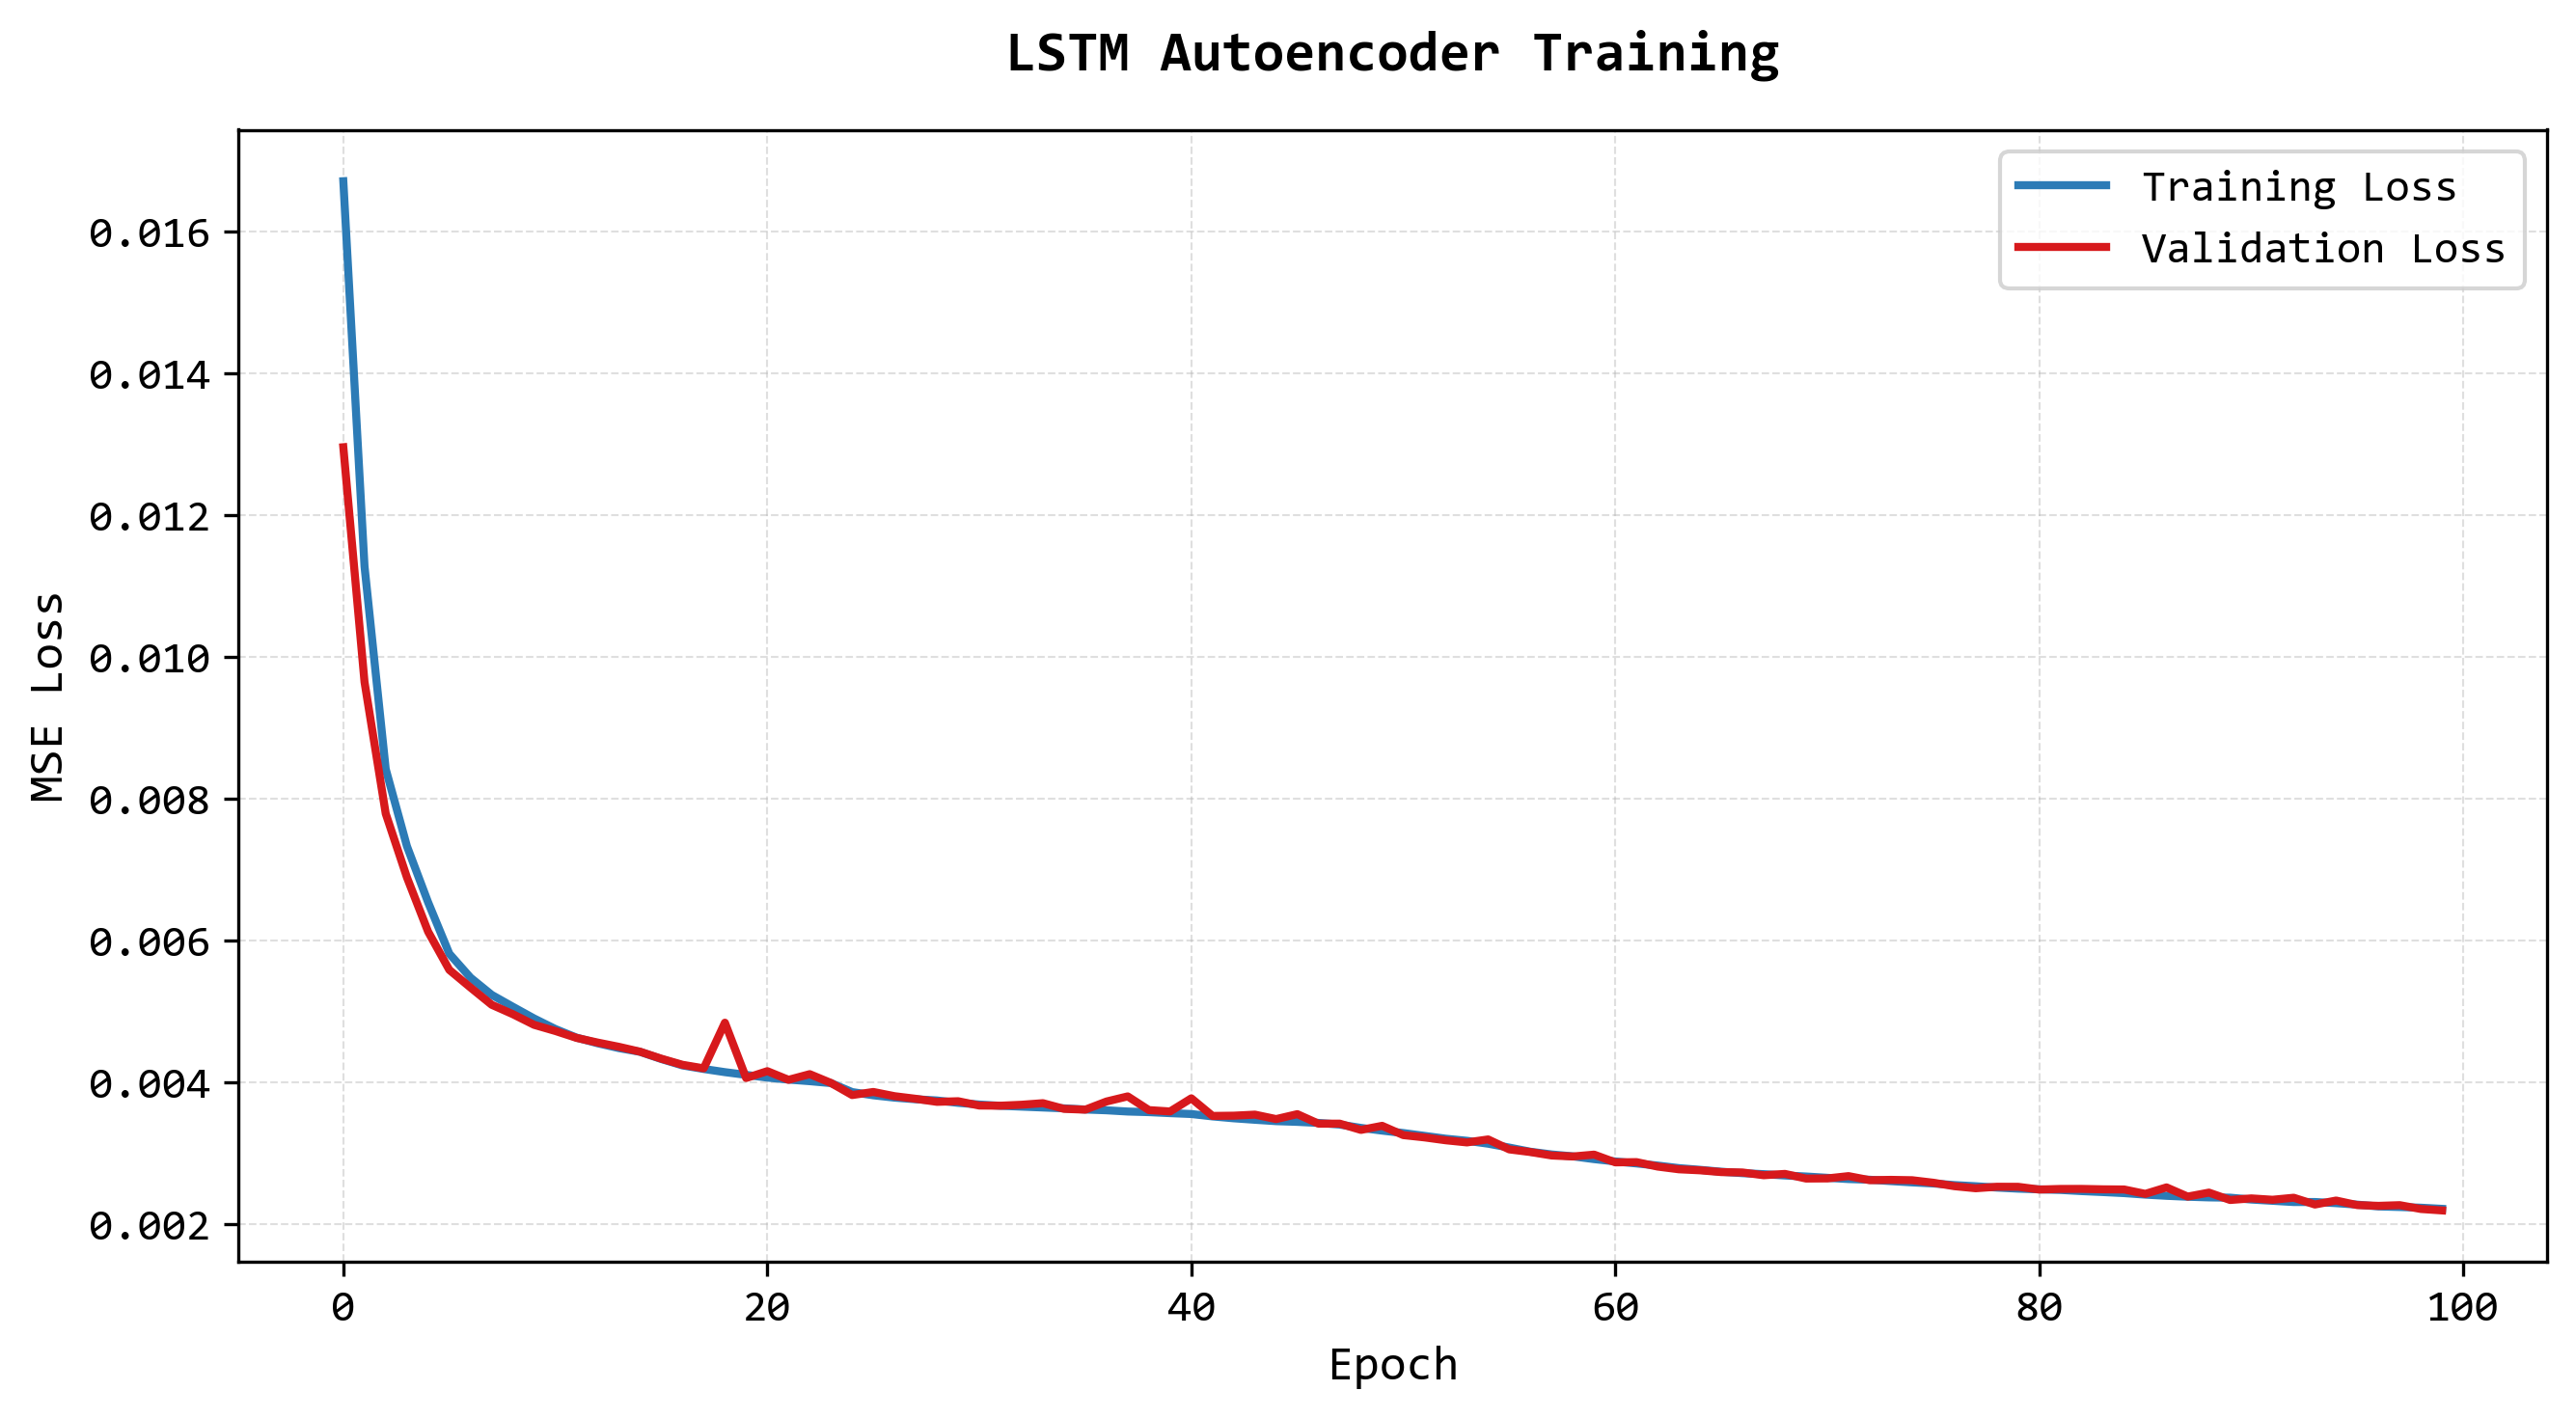

In [112]:
import os
import matplotlib.pyplot as plt
from matplotlib import rcParams


# ==========================================
# Police globale Consolas
# ==========================================

rcParams['font.family'] = 'Consolas'


# ==========================================
# Création du dossier de sauvegarde
# ==========================================

os.makedirs(
    "figures/training",
    exist_ok=True
)


# ==========================================
# Courbe d'apprentissage LSTM Autoencoder
# ==========================================

plt.figure(
   figsize=(9,5),
    dpi=300
)


# ==========================================
# Training Loss
# ==========================================

plt.plot(
    history.history["loss"],
    label="Training Loss",
    linewidth=2,
    color="#2C7BB6"
)


# ==========================================
# Validation Loss
# ==========================================

plt.plot(
    history.history["val_loss"],
    label="Validation Loss",
    linewidth=2,
    color="#D7191C"
)


# ==========================================
# Labels
# ==========================================

plt.xlabel(
    "Epoch",
    fontsize=12,
    fontfamily="Consolas"
)

plt.ylabel(
    "MSE Loss",
    fontsize=12,
    fontfamily="Consolas"
)


# ==========================================
# Titre
# ==========================================

plt.title(
    "LSTM Autoencoder Training",
    fontsize=14,
    fontweight="bold",
    fontfamily="Consolas",
    pad=15
)


# ==========================================
# Légende
# ==========================================

plt.legend(
    fontsize=11
)


# ==========================================
# Ticks
# ==========================================

plt.xticks(
    fontsize=11,
    fontfamily="Consolas"
)

plt.yticks(
    fontsize=11,
    fontfamily="Consolas"
)


# ==========================================
# Grille
# ==========================================

plt.grid(
    True,
    linestyle="--",
    linewidth=0.5,
    alpha=0.4
)


# ==========================================
# Ajustement
# ==========================================

plt.tight_layout()


# ==========================================
# Sauvegarde
# ==========================================

plt.savefig(
    "figures/training/lstm_training_loss.png",
    format="png",
    dpi=300,
    bbox_inches="tight"
)


plt.show()

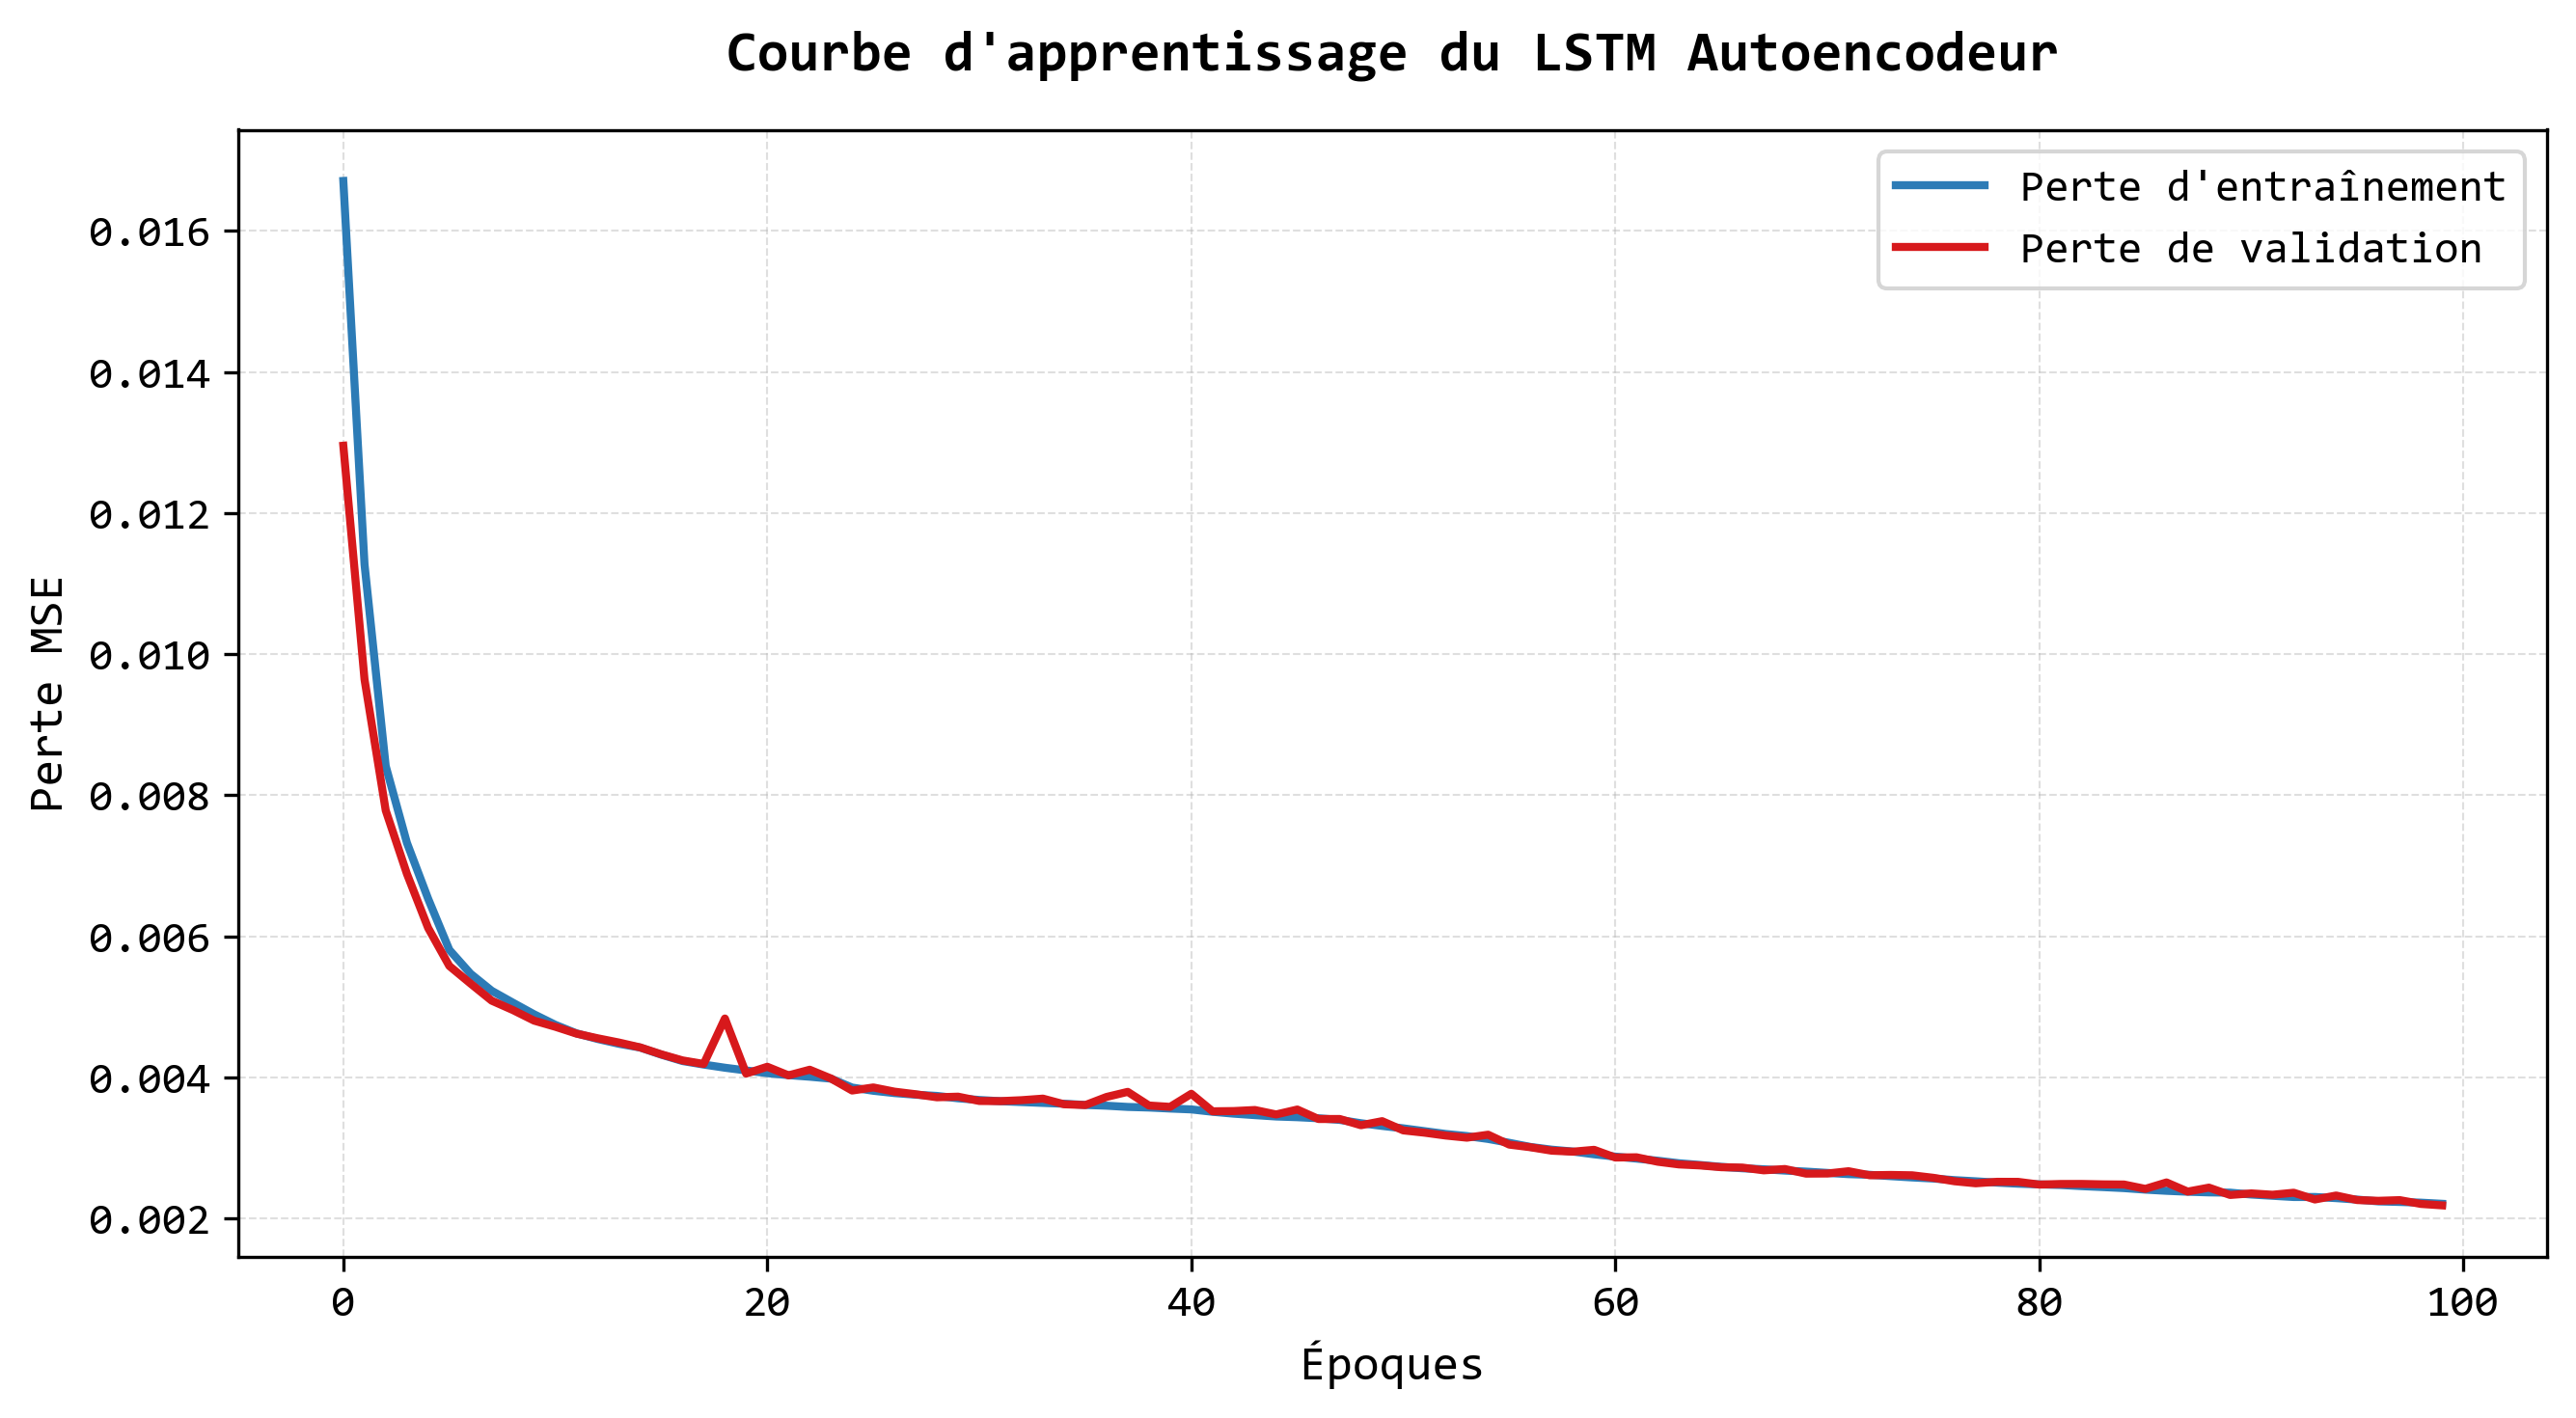

In [115]:
import os
import matplotlib.pyplot as plt
from matplotlib import rcParams


# ==========================================
# Police globale Consolas
# ==========================================

rcParams['font.family'] = 'Consolas'


# ==========================================
# Création du dossier de sauvegarde
# ==========================================

os.makedirs(
    "figures/training",
    exist_ok=True
)


# ==========================================
# Courbe d'apprentissage du LSTM Autoencodeur
# ==========================================

plt.figure(
    figsize=(9,5),
    dpi=300
)


# ==========================================
# Perte d'entraînement
# ==========================================

plt.plot(
    history.history["loss"],
    label="Perte d'entraînement",
    linewidth=2,
    color="#2C7BB6"
)


# ==========================================
# Perte de validation
# ==========================================

plt.plot(
    history.history["val_loss"],
    label="Perte de validation",
    linewidth=2,
    color="#D7191C"
)


# ==========================================
# Labels des axes
# ==========================================

plt.xlabel(
    "Époques",
    fontsize=12,
    fontfamily="Consolas"
)

plt.ylabel(
    "Perte MSE",
    fontsize=12,
    fontfamily="Consolas"
)


# ==========================================
# Titre
# ==========================================

plt.title(
    "Courbe d'apprentissage du LSTM Autoencodeur",
    fontsize=14,
    fontweight="bold",
    fontfamily="Consolas",
    pad=15
)


# ==========================================
# Légende
# ==========================================

plt.legend(
    fontsize=11
)


# ==========================================
# Graduations des axes
# ==========================================

plt.xticks(
    fontsize=11,
    fontfamily="Consolas"
)

plt.yticks(
    fontsize=11,
    fontfamily="Consolas"
)


# ==========================================
# Grille
# ==========================================

plt.grid(
    True,
    linestyle="--",
    linewidth=0.5,
    alpha=0.4
)


# ==========================================
# Ajustement de la figure
# ==========================================

plt.tight_layout()


# ==========================================
# Sauvegarde PNG haute résolution
# ==========================================

plt.savefig(
    "figures/training/fr_lstm_training_loss.png",
    format="png",
    dpi=300,
    bbox_inches="tight"
)


# ==========================================
# Affichage
# ==========================================

plt.show()

In [42]:
# ===================================
# Chargement du meilleur modèle
# Cellule 9
# ===================================


best_model = tf.keras.models.load_model(
    "models/lstm_autoencoder_best.keras"
)



print(
    "Meilleur modèle chargé avec succès"
)

Meilleur modèle chargé avec succès


In [86]:
# ===================================
# Reconstruction des données test
# ===================================


X_test_reconstructed = best_model.predict(X_test_lstm, verbose=1)

# ===================================
# Calcul erreur de reconstruction
# ===================================


reconstruction_error = np.mean(np.square(X_test_lstm - X_test_reconstructed ), axis=(1, 2))

21875/21875 [==============================] - 214s 10ms/step


In [87]:
# ===================================
# Tableau des résultats
# ===================================

results = pd.DataFrame({ "reconstruction_error": reconstruction_error, "true_label":  y_test_lstm})

results.head()

,reconstruction_error,true_label
0,0.002204,0
1,0.003630,0
2,0.004879,0
3,0.006640,0
4,0.006543,0


In [88]:
# ===================================
# Sauvegarde des erreurs
# ===================================


results.to_csv("results/lstm_reconstruction_errors.csv", index=False)

print("Résultats de reconstruction sauvegardés")

Résultats de reconstruction sauvegardés


In [89]:
# ===================================
# Reconstruction validation
# ===================================


X_val_reconstructed = best_model.predict( X_val_lstm, verbose=1)

4236/4236 [==============================] - 39s 9ms/step


In [90]:
# ===================================
# Erreur de reconstruction validation
# ===================================

val_reconstruction_error = np.mean( np.square(X_val_lstm - X_val_reconstructed), axis=(1, 2))

In [91]:
# ===================================
# Seuil d'anomalie
# ===================================


threshold = np.percentile(val_reconstruction_error, 95)

print("Seuil d'anomalie :", threshold)

Seuil d'anomalie : 0.0035584781539352126


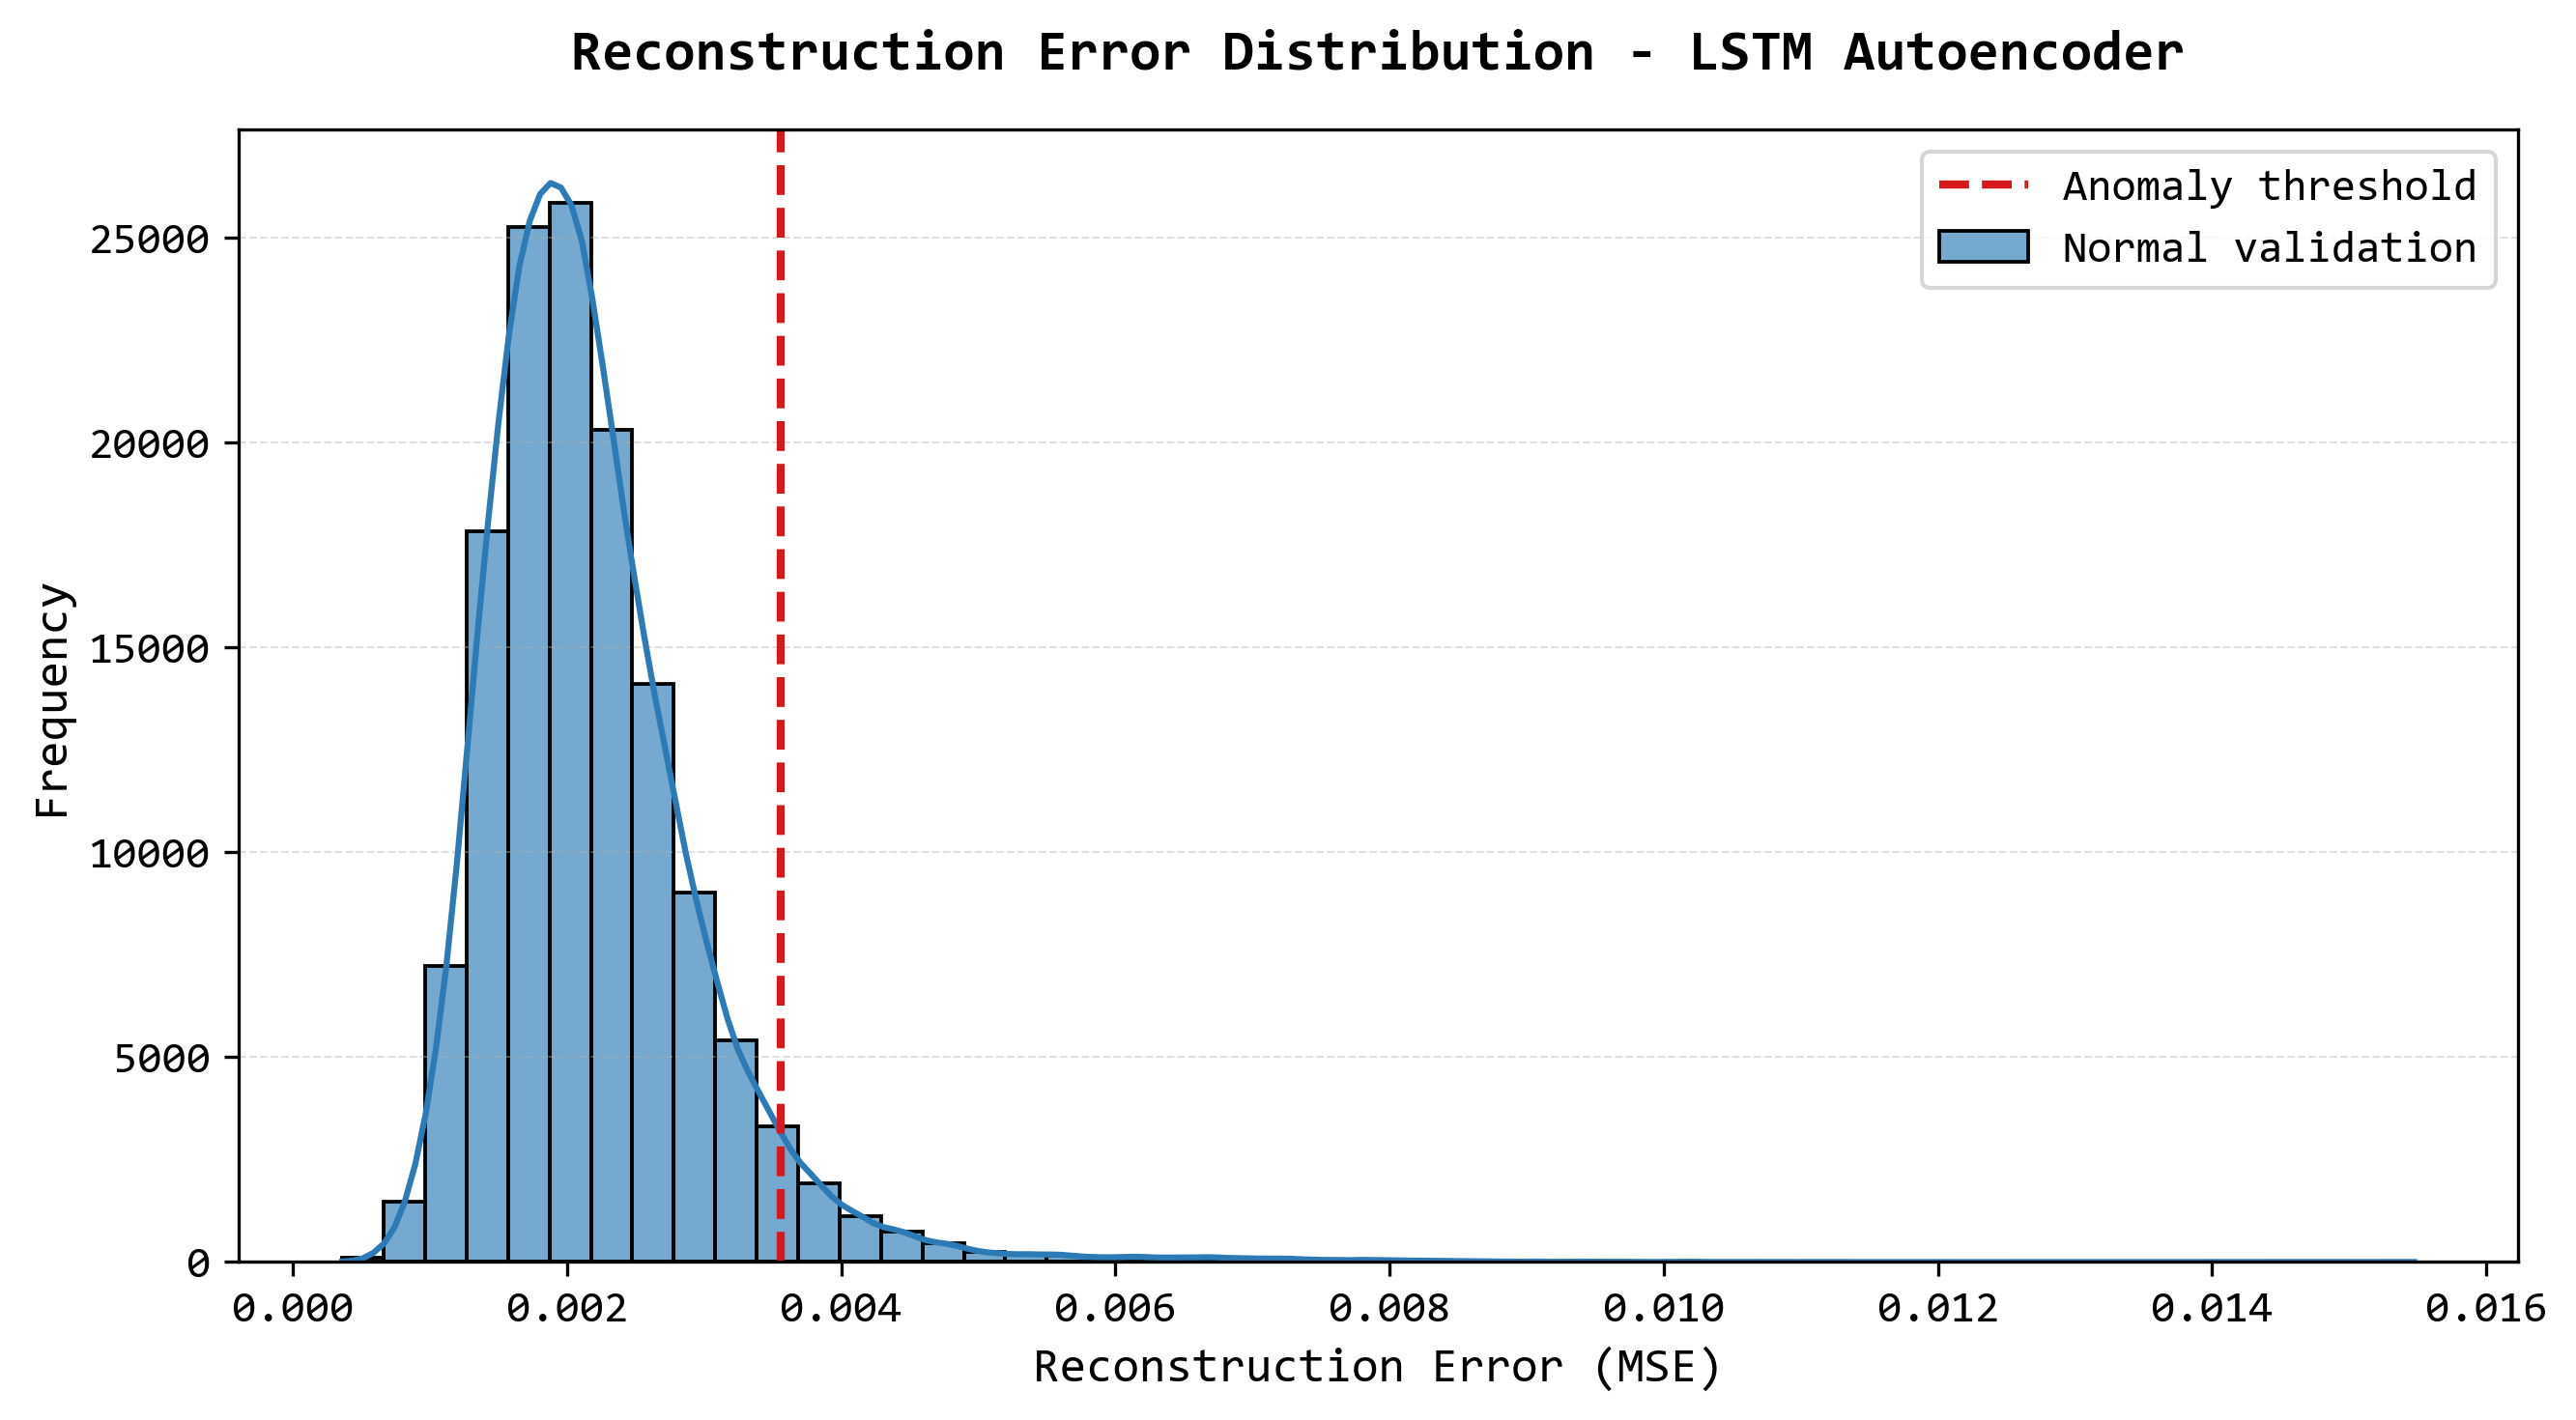

In [111]:
import os
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import rcParams


# ==========================================
# Police globale Consolas
# ==========================================

rcParams['font.family'] = 'Consolas'


# ==========================================
# Création du dossier de sauvegarde
# ==========================================

os.makedirs(
    "figures/evaluation",
    exist_ok=True
)


# ==========================================
# Distribution des erreurs de reconstruction
# ==========================================

plt.figure(
    figsize=(9,5),
    dpi=300
)


# ==========================================
# Distribution erreur validation
# ==========================================

sns.histplot(
    val_reconstruction_error,
    bins=50,
    kde=True,
    color="#2C7BB6",
    alpha=0.65,
    label="Normal validation"
)


# ==========================================
# Seuil d'anomalie
# ==========================================

plt.axvline(
    threshold,
    color="#D7191C",
    linestyle="--",
    linewidth=2,
    label="Anomaly threshold"
)


# ==========================================
# Labels des axes
# ==========================================

plt.xlabel(
    "Reconstruction Error (MSE)",
    fontsize=12,
    fontfamily="Consolas"
)


plt.ylabel(
    "Frequency",
    fontsize=12,
    fontfamily="Consolas"
)


# ==========================================
# Titre
# ==========================================

plt.title(
    "Reconstruction Error Distribution - LSTM Autoencoder",
    fontsize=14,
    fontweight="bold",
    fontfamily="Consolas",
    pad=15
)


# ==========================================
# Légende
# ==========================================

plt.legend(
    fontsize=11
)


# ==========================================
# Personnalisation des ticks
# ==========================================

plt.xticks(
    fontsize=11,
    fontfamily="Consolas"
)

plt.yticks(
    fontsize=11,
    fontfamily="Consolas"
)


# ==========================================
# Grille
# ==========================================

plt.grid(
    axis="y",
    linestyle="--",
    linewidth=0.5,
    alpha=0.4
)


# ==========================================
# Ajustement
# ==========================================

plt.tight_layout()


# ==========================================
# Sauvegarde PNG haute résolution
# ==========================================

plt.savefig(
    "figures/evaluation/lstm_threshold_distribution.png",
    format="png",
    dpi=300,
    bbox_inches="tight"
)


# ==========================================
# Affichage
# ==========================================

plt.show()

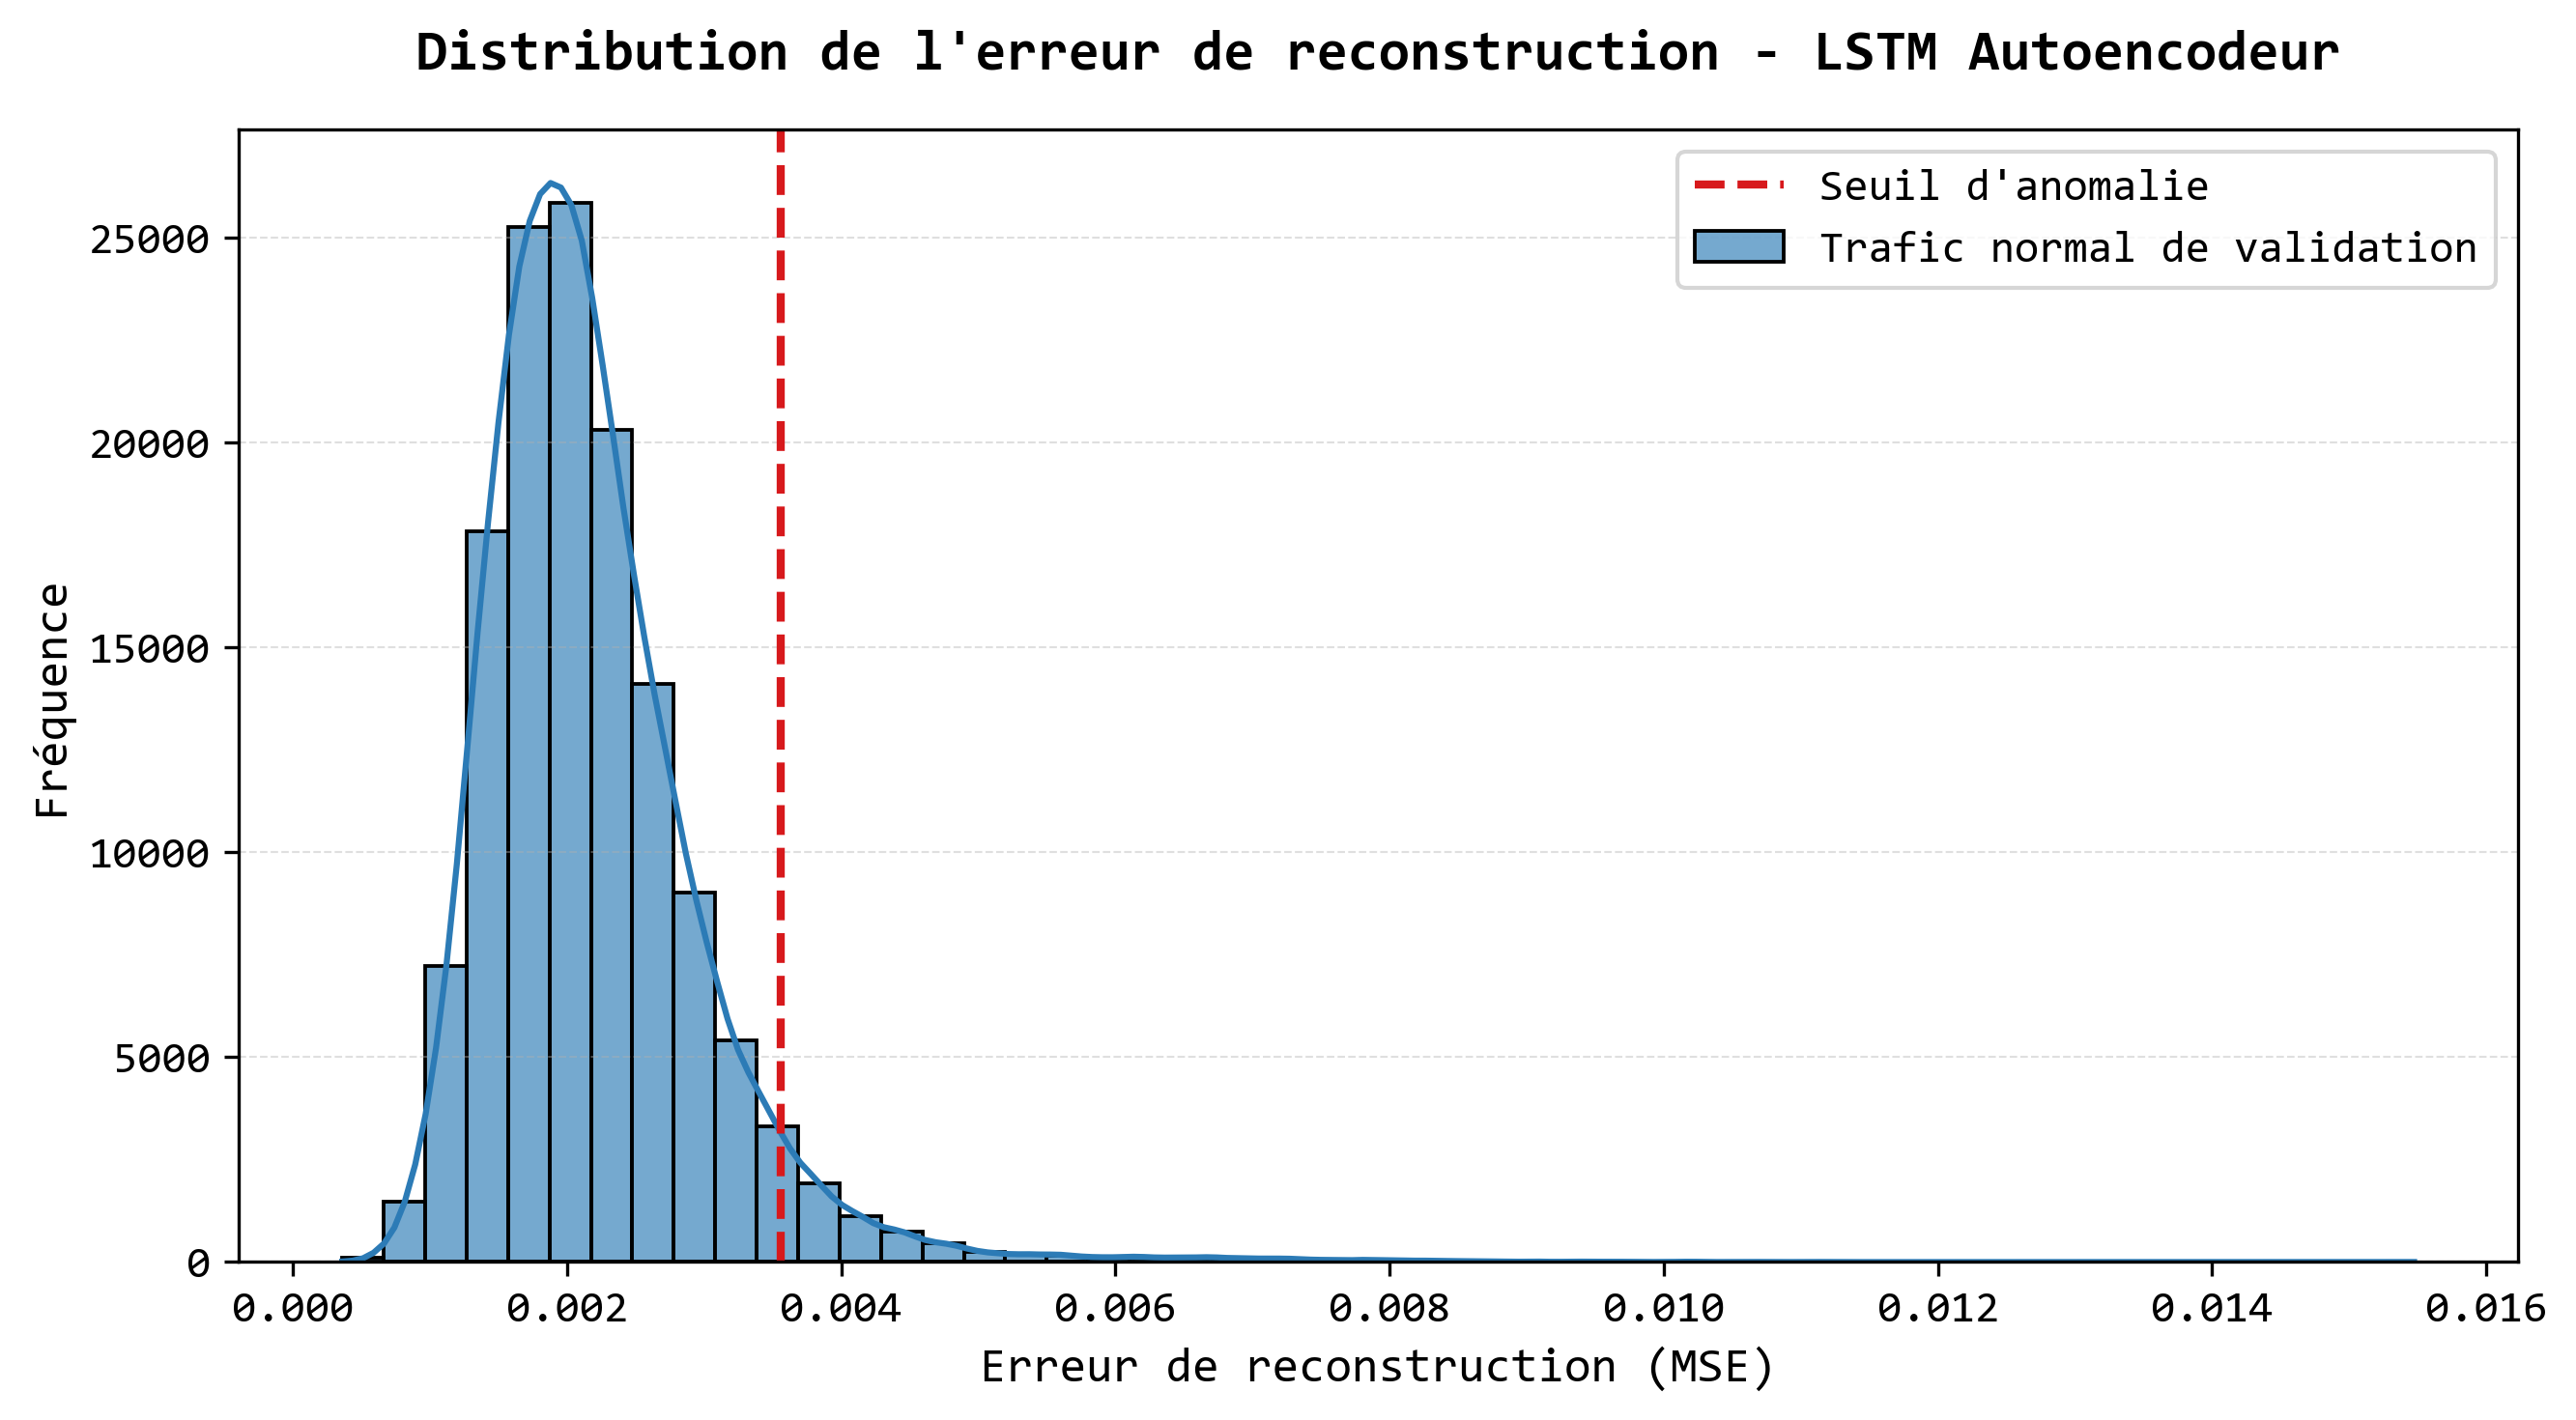

In [116]:
import os
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import rcParams


# ==========================================
# Police globale Consolas
# ==========================================

rcParams['font.family'] = 'Consolas'


# ==========================================
# Création du dossier de sauvegarde
# ==========================================

os.makedirs(
    "figures/evaluation",
    exist_ok=True
)


# ==========================================
# Distribution des erreurs de reconstruction
# ==========================================

plt.figure(
    figsize=(9,5),
    dpi=300
)


# ==========================================
# Distribution des erreurs de validation
# ==========================================

sns.histplot(
    val_reconstruction_error,
    bins=50,
    kde=True,
    color="#2C7BB6",
    alpha=0.65,
    label="Trafic normal de validation"
)


# ==========================================
# Seuil d'anomalie
# ==========================================

plt.axvline(
    threshold,
    color="#D7191C",
    linestyle="--",
    linewidth=2,
    label="Seuil d'anomalie"
)


# ==========================================
# Labels des axes
# ==========================================

plt.xlabel(
    "Erreur de reconstruction (MSE)",
    fontsize=12,
    fontfamily="Consolas"
)


plt.ylabel(
    "Fréquence",
    fontsize=12,
    fontfamily="Consolas"
)


# ==========================================
# Titre
# ==========================================

plt.title(
    "Distribution de l'erreur de reconstruction - LSTM Autoencodeur",
    fontsize=14,
    fontweight="bold",
    fontfamily="Consolas",
    pad=15
)


# ==========================================
# Légende
# ==========================================

plt.legend(
    fontsize=11
)


# ==========================================
# Personnalisation des graduations
# ==========================================

plt.xticks(
    fontsize=11,
    fontfamily="Consolas"
)

plt.yticks(
    fontsize=11,
    fontfamily="Consolas"
)


# ==========================================
# Grille
# ==========================================

plt.grid(
    axis="y",
    linestyle="--",
    linewidth=0.5,
    alpha=0.4
)


# ==========================================
# Ajustement de la figure
# ==========================================

plt.tight_layout()


# ==========================================
# Sauvegarde PNG haute résolution
# ==========================================

plt.savefig(
    "figures/evaluation/fr_lstm_threshold_distribution.png",
    format="png",
    dpi=300,
    bbox_inches="tight"
)


# ==========================================
# Affichage
# ==========================================

plt.show()

In [56]:
# ===================================
# Détection des anomalies
# Cellule 11
# ===================================


y_pred = (

    reconstruction_error > threshold

).astype(int)



print(
    "Prédictions générées avec succès"
)

Prédictions générées avec succès


In [61]:
# ===================================
# Sauvegarde des prédictions
# ===================================


comparison.to_csv(

    "results/lstm_predictions.csv",

    index=False

)



print(
    "Prédictions sauvegardées"
)

Prédictions sauvegardées


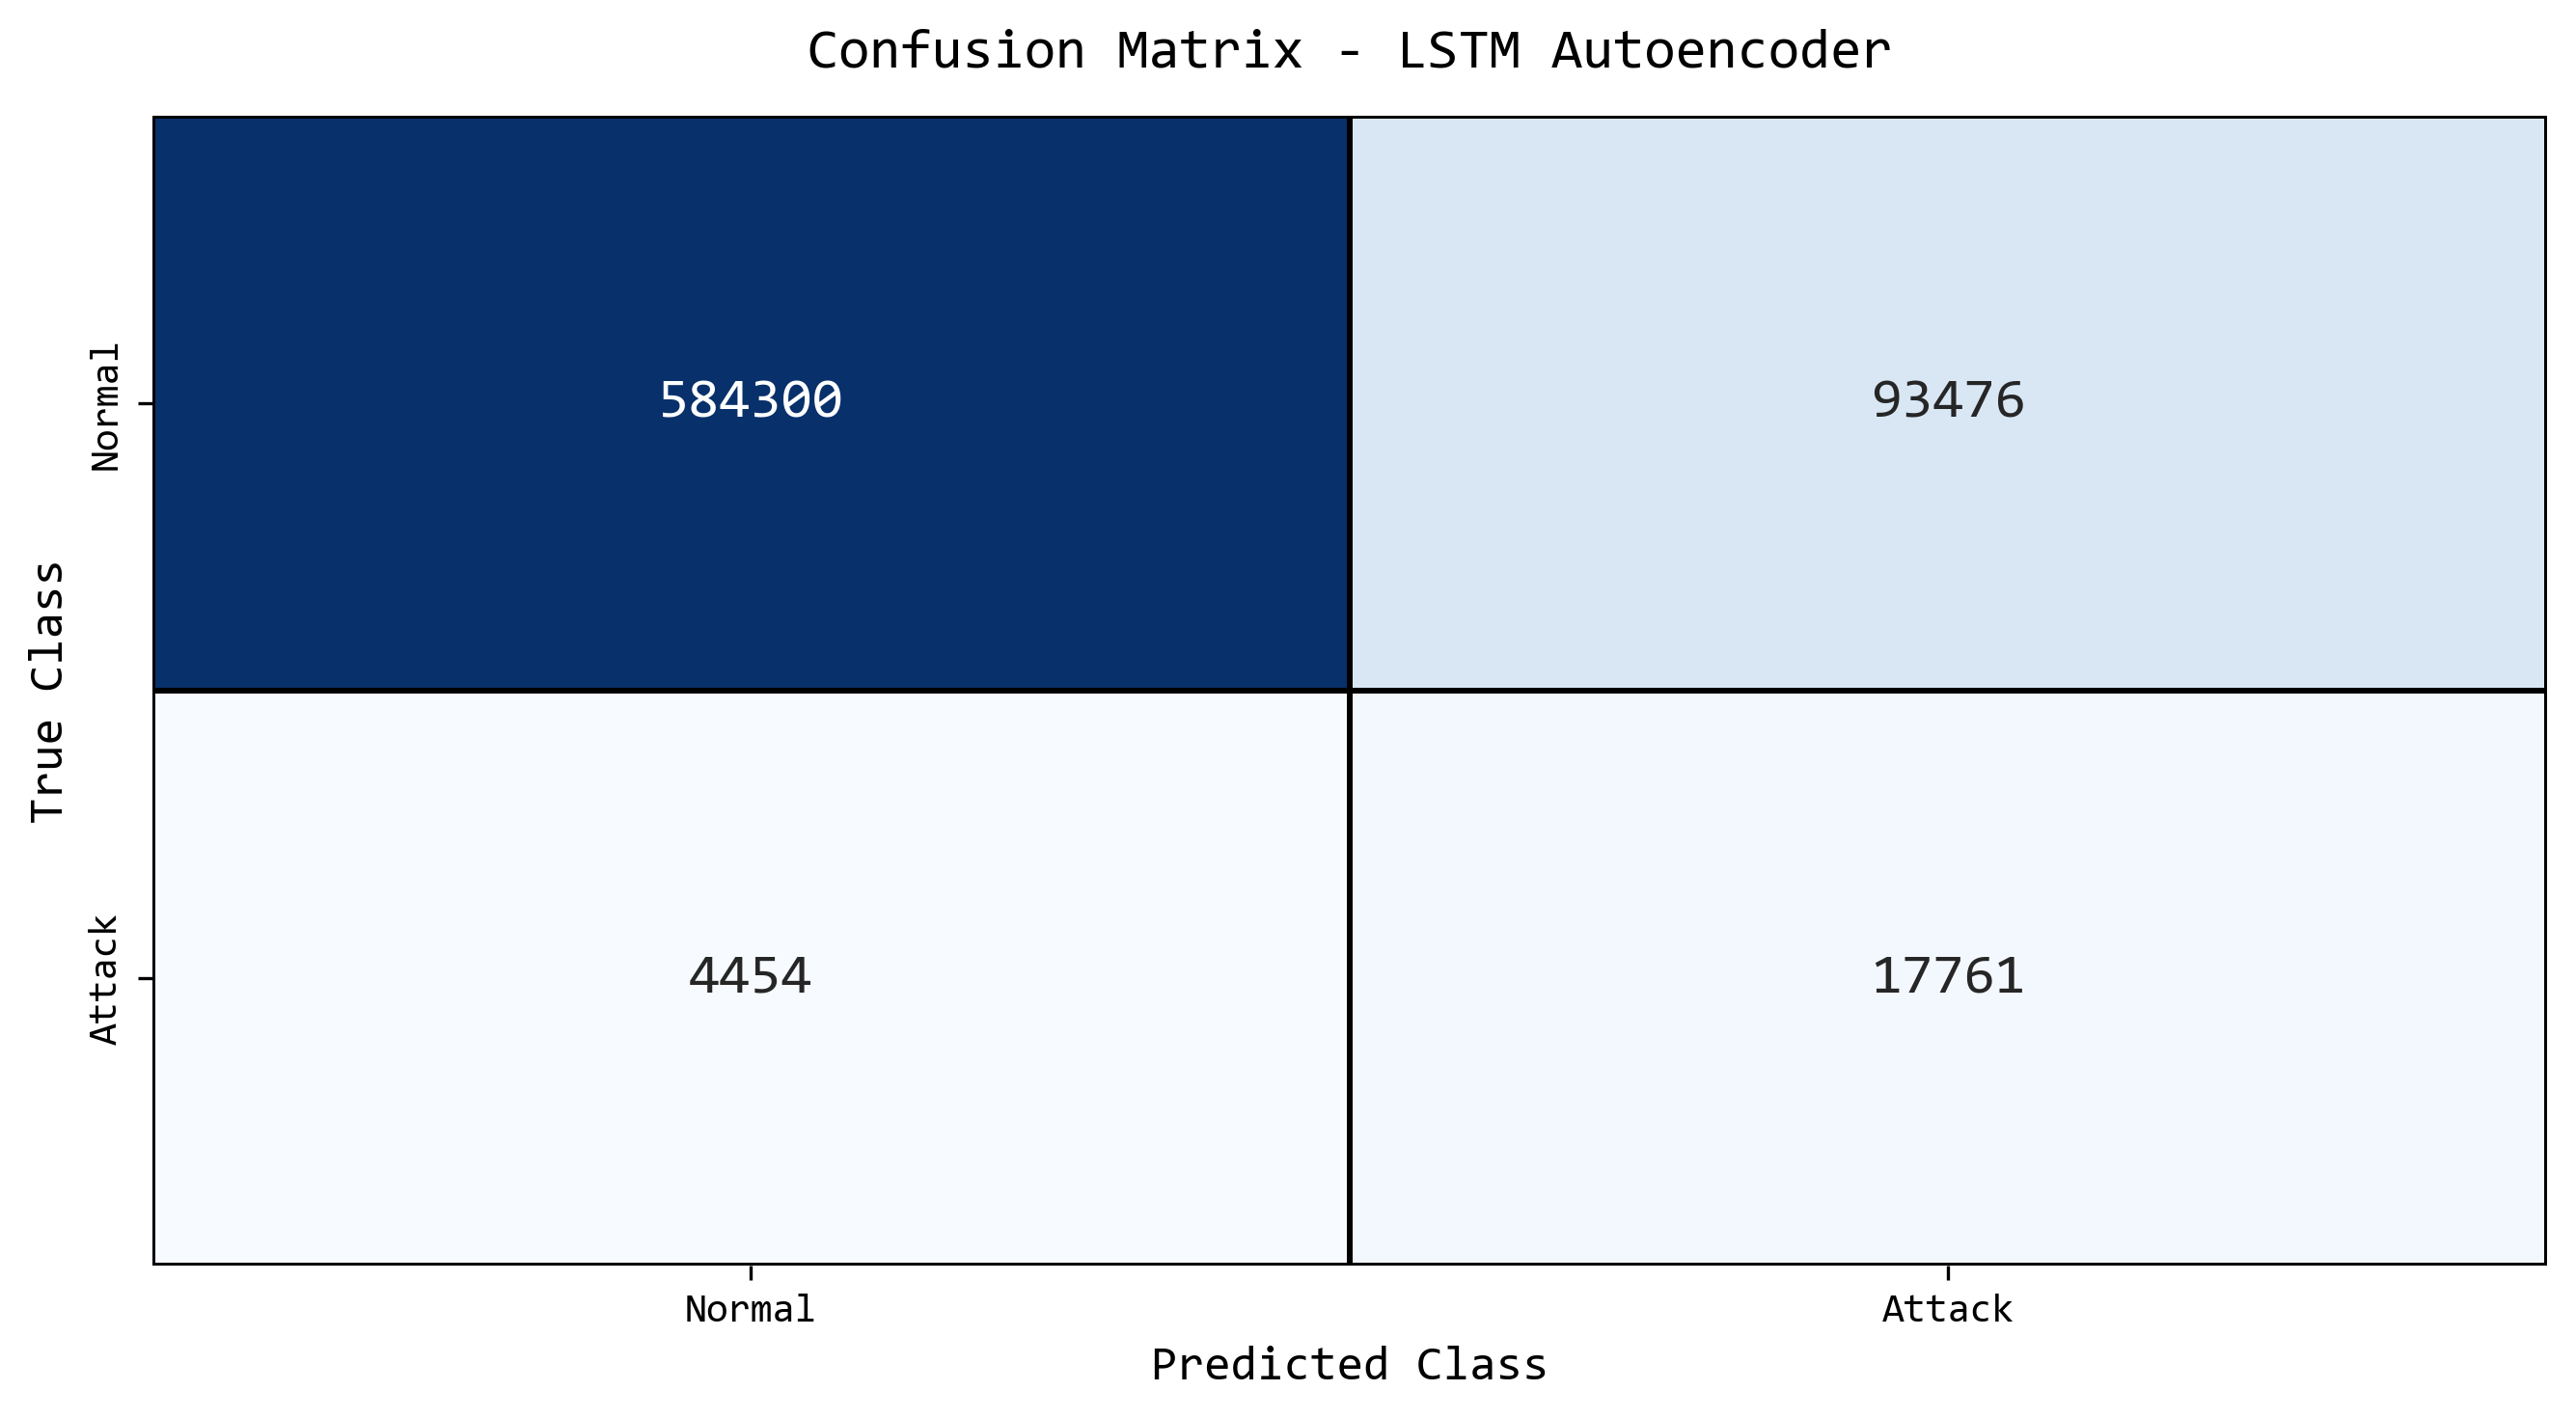

In [110]:
# ===================================
# Visualisation matrice de confusion
# ===================================


plt.rcParams["font.family"] = "Consolas"


fig, ax = plt.subplots(

   figsize=(9,5),

    dpi=300

)


sns.heatmap(

    cm,

    annot=True,

    fmt="d",

    cmap="Blues",

    cbar=False,

    linewidths=1,

    linecolor="black",

    xticklabels=[
        "Normal",
        "Attack"
    ],

    yticklabels=[
        "Normal",
        "Attack"
    ],

    annot_kws={
        "fontsize": 14,
        "fontfamily": "Consolas"
    },

    ax=ax

)


ax.set_xlabel(

    "Predicted Class",

    fontsize=12,

    fontfamily="Consolas"

)


ax.set_ylabel(

    "True Class",

    fontsize=12,

    fontfamily="Consolas"

)


ax.set_title(

    "Confusion Matrix - LSTM Autoencoder",

    fontsize=14,

    fontfamily="Consolas",

    pad=12

)



# ===================================
# Sauvegarde PNG
# ===================================


fig.savefig(

    "figures/evaluation/lstm_confusion_matrix.png",

    dpi=300,

    bbox_inches="tight"

)

plt.tight_layout()

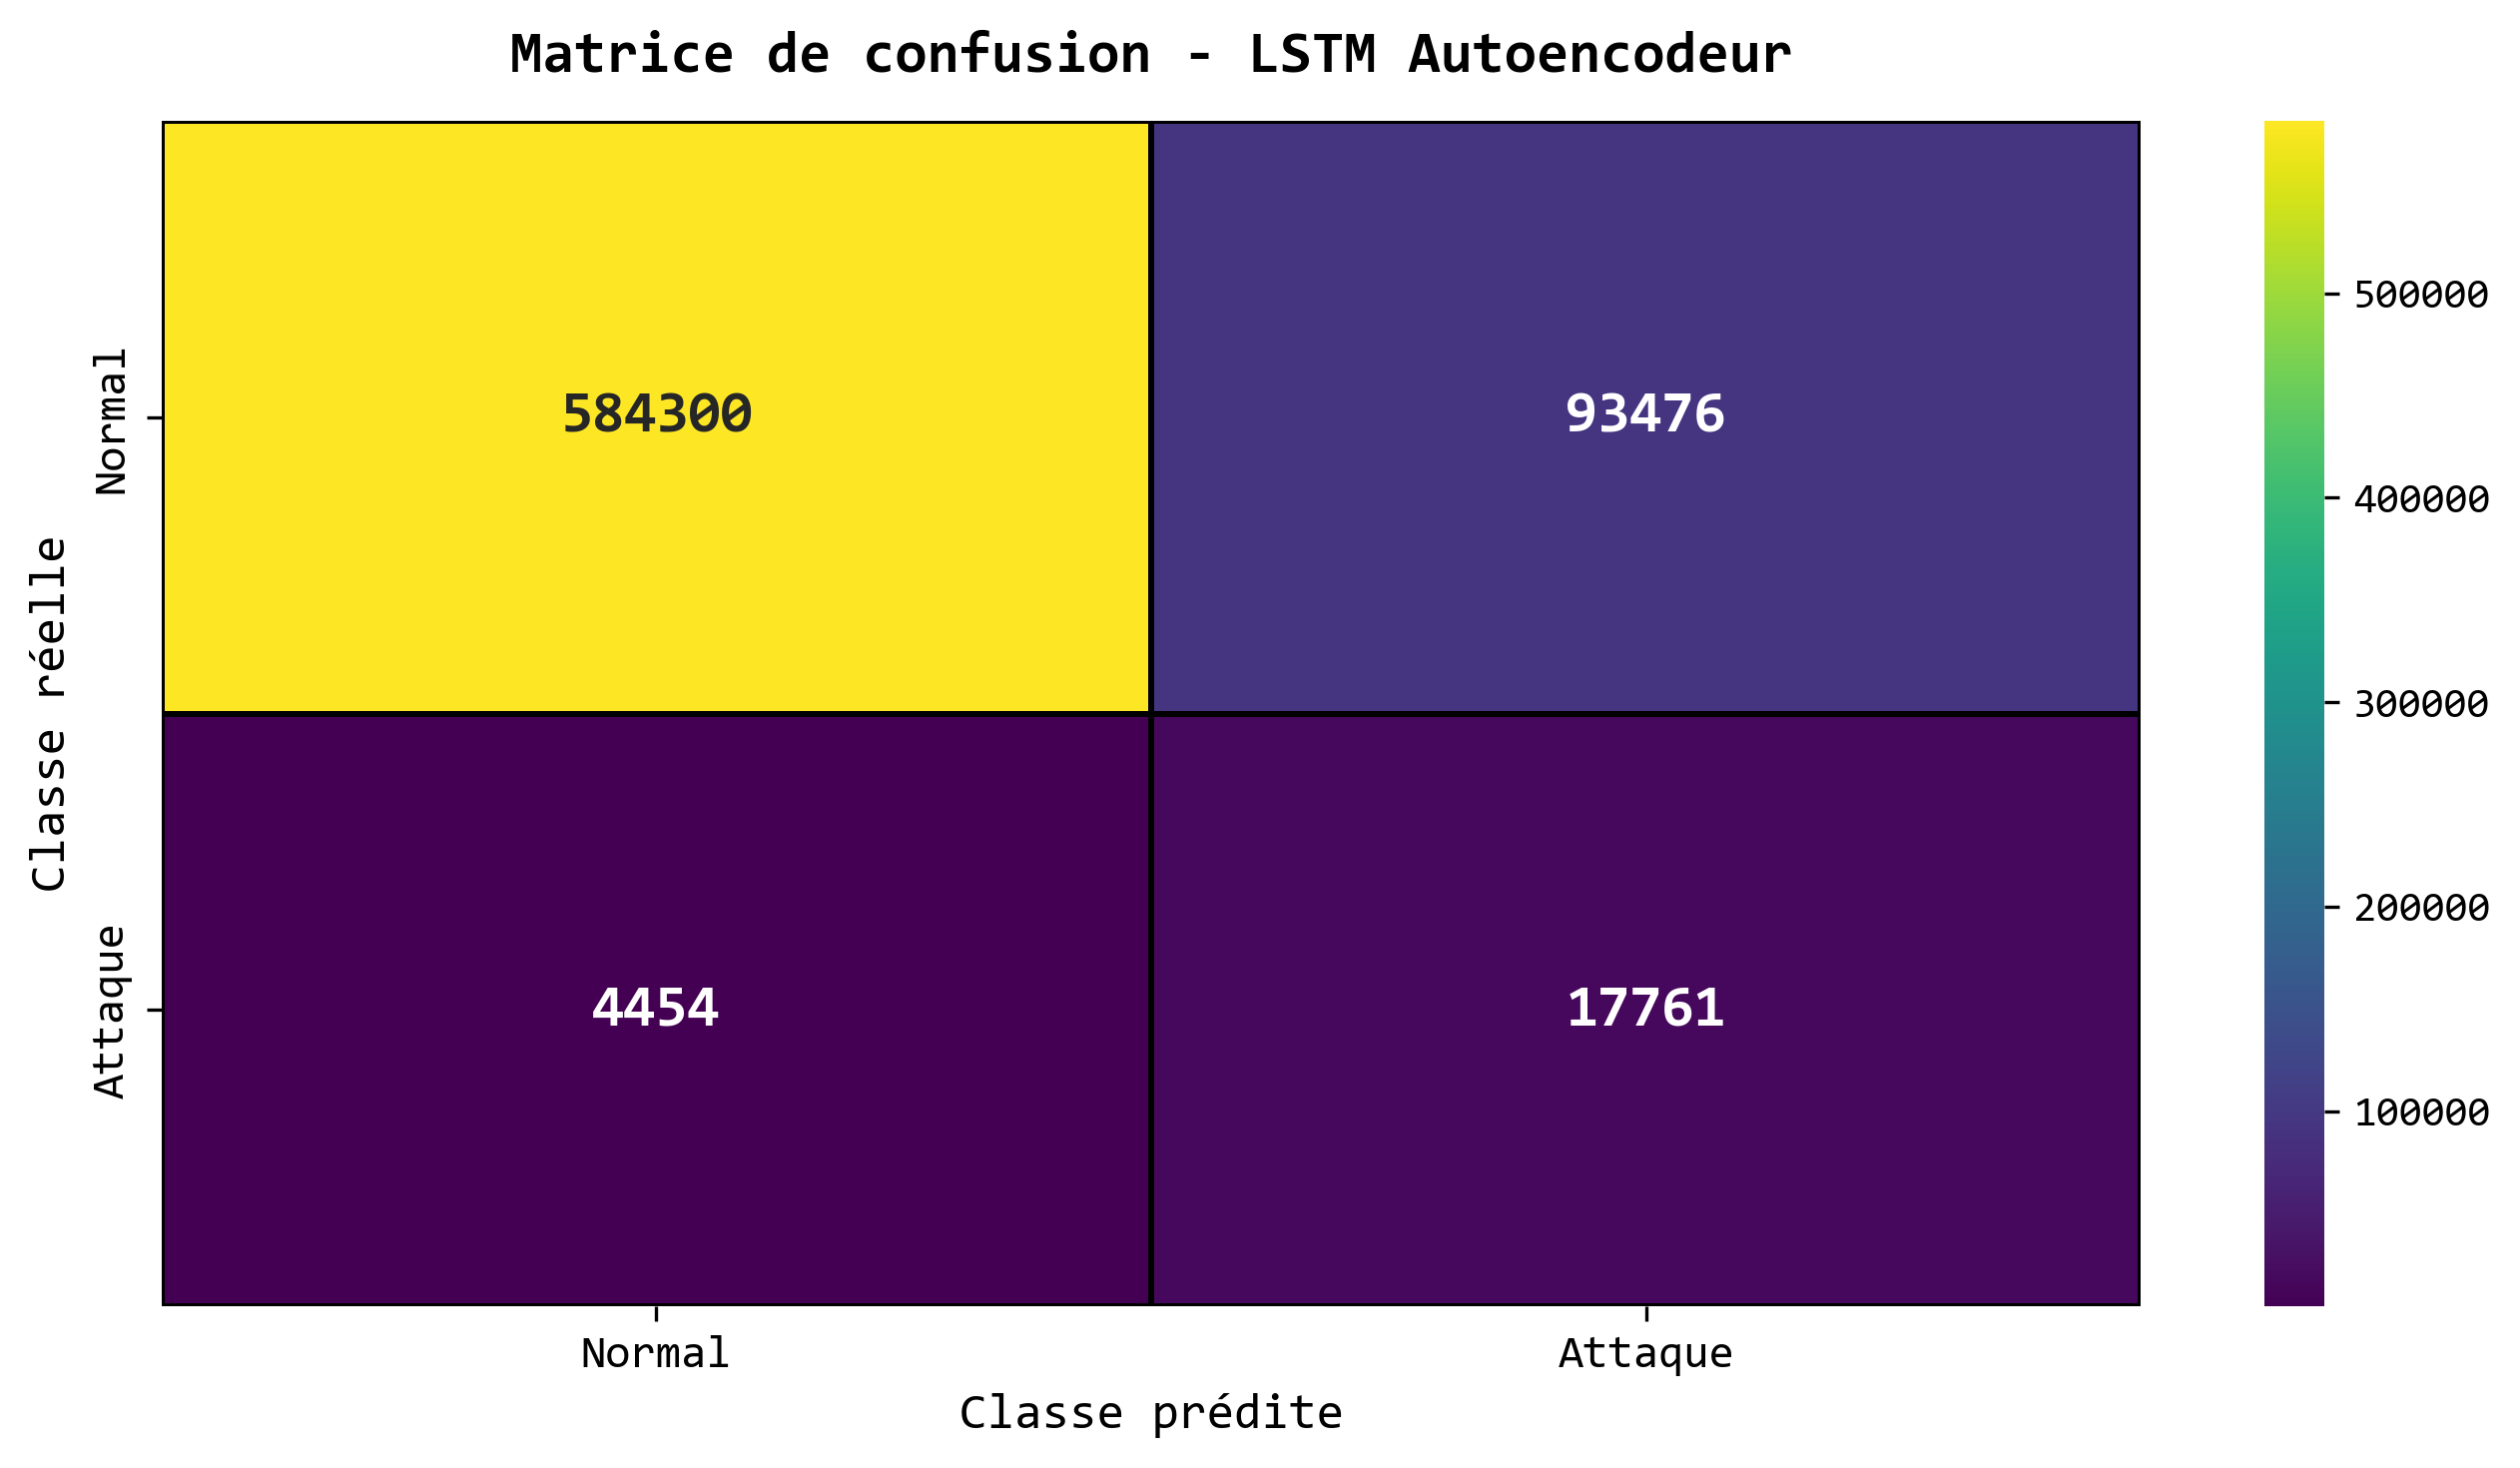

In [117]:
import os
import matplotlib.pyplot as plt
import seaborn as sns


# ==========================================
# Police globale Consolas
# ==========================================

plt.rcParams["font.family"] = "Consolas"


# ==========================================
# Création du dossier de sauvegarde
# ==========================================

os.makedirs(
    "figures/evaluation",
    exist_ok=True
)


# ==========================================
# Visualisation de la matrice de confusion
# ==========================================

fig, ax = plt.subplots(
    figsize=(9,5),
    dpi=300
)


# ==========================================
# Matrice de confusion
# ==========================================

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="viridis",
    cbar=True,
    linewidths=1,
    linecolor="black",

    xticklabels=[
        "Normal",
        "Attaque"
    ],

    yticklabels=[
        "Normal",
        "Attaque"
    ],

    annot_kws={
        "fontsize":14,
        "fontfamily":"Consolas",
        "fontweight":"bold"
    },

    ax=ax
)


# ==========================================
# Labels des axes
# ==========================================

ax.set_xlabel(
    "Classe prédite",
    fontsize=12,
    fontfamily="Consolas"
)


ax.set_ylabel(
    "Classe réelle",
    fontsize=12,
    fontfamily="Consolas"
)


# ==========================================
# Titre
# ==========================================

ax.set_title(
    "Matrice de confusion - LSTM Autoencodeur",
    fontsize=14,
    fontweight="bold",
    fontfamily="Consolas",
    pad=12
)


# ==========================================
# Personnalisation des graduations
# ==========================================

ax.tick_params(
    axis="both",
    labelsize=11
)


for label in ax.get_xticklabels():
    label.set_fontname("Consolas")


for label in ax.get_yticklabels():
    label.set_fontname("Consolas")


# ==========================================
# Police de la barre de couleur
# ==========================================

if ax.collections[0].colorbar is not None:

    cbar = ax.collections[0].colorbar

    cbar.ax.tick_params(
        labelsize=10
    )

    for label in cbar.ax.get_yticklabels():
        label.set_fontname("Consolas")


# ==========================================
# Ajustement
# ==========================================

plt.tight_layout()


# ==========================================
# Sauvegarde PNG haute résolution
# ==========================================

fig.savefig(
    "figures/evaluation/fr_lstm_confusion_matrix.png",
    format="png",
    dpi=300,
    bbox_inches="tight"
)


# ==========================================
# Affichage
# ==========================================

plt.show()

In [95]:
# ===================================
# Métriques d'évaluation
# ===================================


accuracy = accuracy_score(

    y_test_lstm,

    y_pred

)


precision = precision_score(

    y_test_lstm,

    y_pred,

    zero_division=0

)


recall = recall_score(

    y_test_lstm,

    y_pred,

    zero_division=0

)


f1 = f1_score(

    y_test_lstm,

    y_pred,

    zero_division=0

)

In [69]:
# ===================================
# Classification Report
# ===================================


report = classification_report(

    y_test_lstm,

    y_pred,

    target_names=[
        "Normal",
        "Attack"
    ],

    digits=4,

    zero_division=0

)


print(report)

              precision    recall  f1-score   support

      Normal     0.9924    0.8621    0.9227    677776
      Attack     0.1597    0.7995    0.2662     22215

    accuracy                         0.8601    699991
   macro avg     0.5761    0.8308    0.5944    699991
weighted avg     0.9660    0.8601    0.9018    699991



In [70]:
# ===================================
# Tableau des métriques
# ===================================


metrics = pd.DataFrame({

    "Metric": [

        "Accuracy",

        "Precision",

        "Recall",

        "F1-score"

    ],

    "Value": [

        accuracy,

        precision,

        recall,

        f1

    ]

})


metrics

,Metric,Value
0,Accuracy,0.860098
1,Precision,0.159668
2,Recall,0.799505
3,F1-score,0.266178


In [71]:
# ===================================
# Sauvegarde des métriques
# ===================================


metrics.to_csv(

    "results/lstm_metrics.csv",

    index=False

)



print(
    "Métriques sauvegardées"
)

Métriques sauvegardées


In [97]:
# ===================================
# Distribution des erreurs
# ===================================


plt.rcParams["font.family"] = "Consolas"



normal_errors = results.loc[

    results["true_label"] == 0,

    "reconstruction_error"

].values



attack_errors = results.loc[

    results["true_label"] == 1,

    "reconstruction_error"

].values

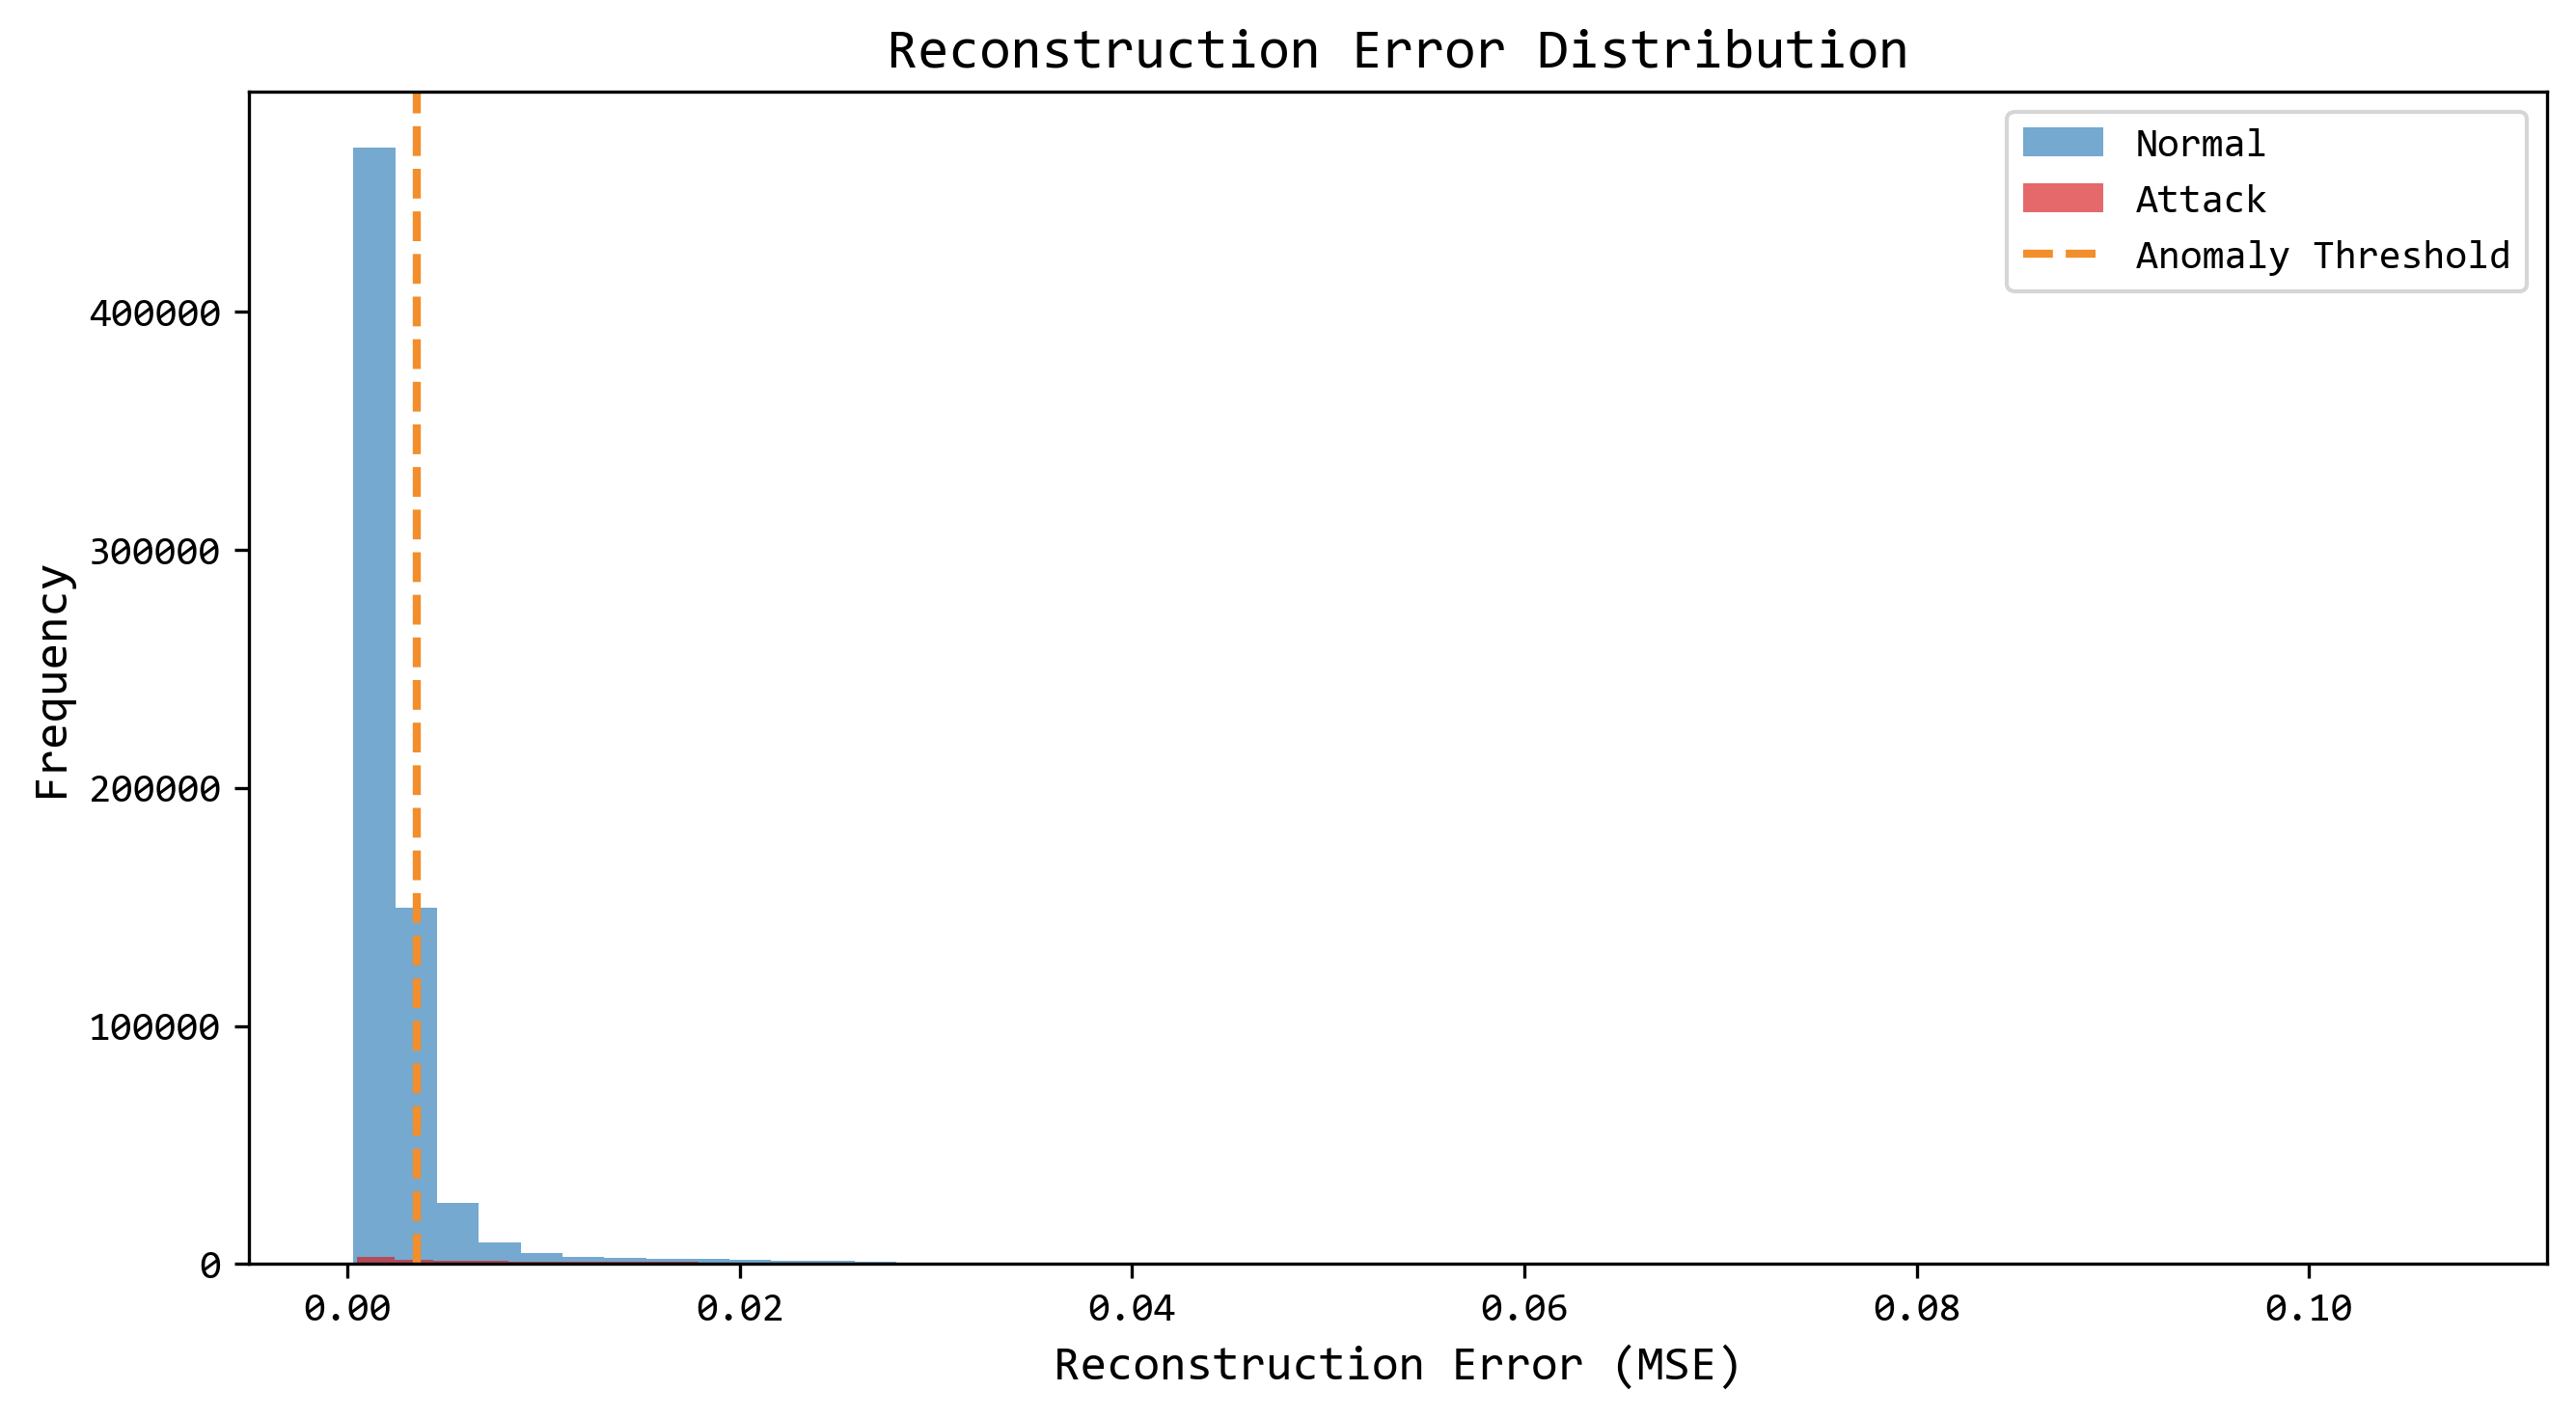

In [109]:
# ===================================
# Histogramme MSE
# ===================================


fig, ax = plt.subplots(

    figsize=(9,5),

    dpi=300

)



ax.hist(

    normal_errors,

    bins=50,

    alpha=0.65,

    color="#2C7BB6",

    label="Normal"

)



ax.hist(

    attack_errors,

    bins=50,

    alpha=0.65,

    color="#D7191C",

    label="Attack"

)



ax.axvline(

    threshold,

    color="#F28E2B",

    linestyle="--",

    linewidth=2,

    label="Anomaly Threshold"

)



ax.set_xlabel(

    "Reconstruction Error (MSE)",

    fontsize=12,

    fontfamily="Consolas"

)



ax.set_ylabel(

    "Frequency",

    fontsize=12,

    fontfamily="Consolas"

)



ax.set_title(

    "Reconstruction Error Distribution",

    fontsize=14,

    fontfamily="Consolas"

)



ax.legend(

    prop={
        "family": "Consolas",
        "size": 10
    }

)


# ===================================
# Sauvegarde PNG
# ===================================


fig.savefig(

    "figures/evaluation/lstm_error_distribution.png",

    dpi=300,

    bbox_inches="tight"

)
plt.tight_layout()

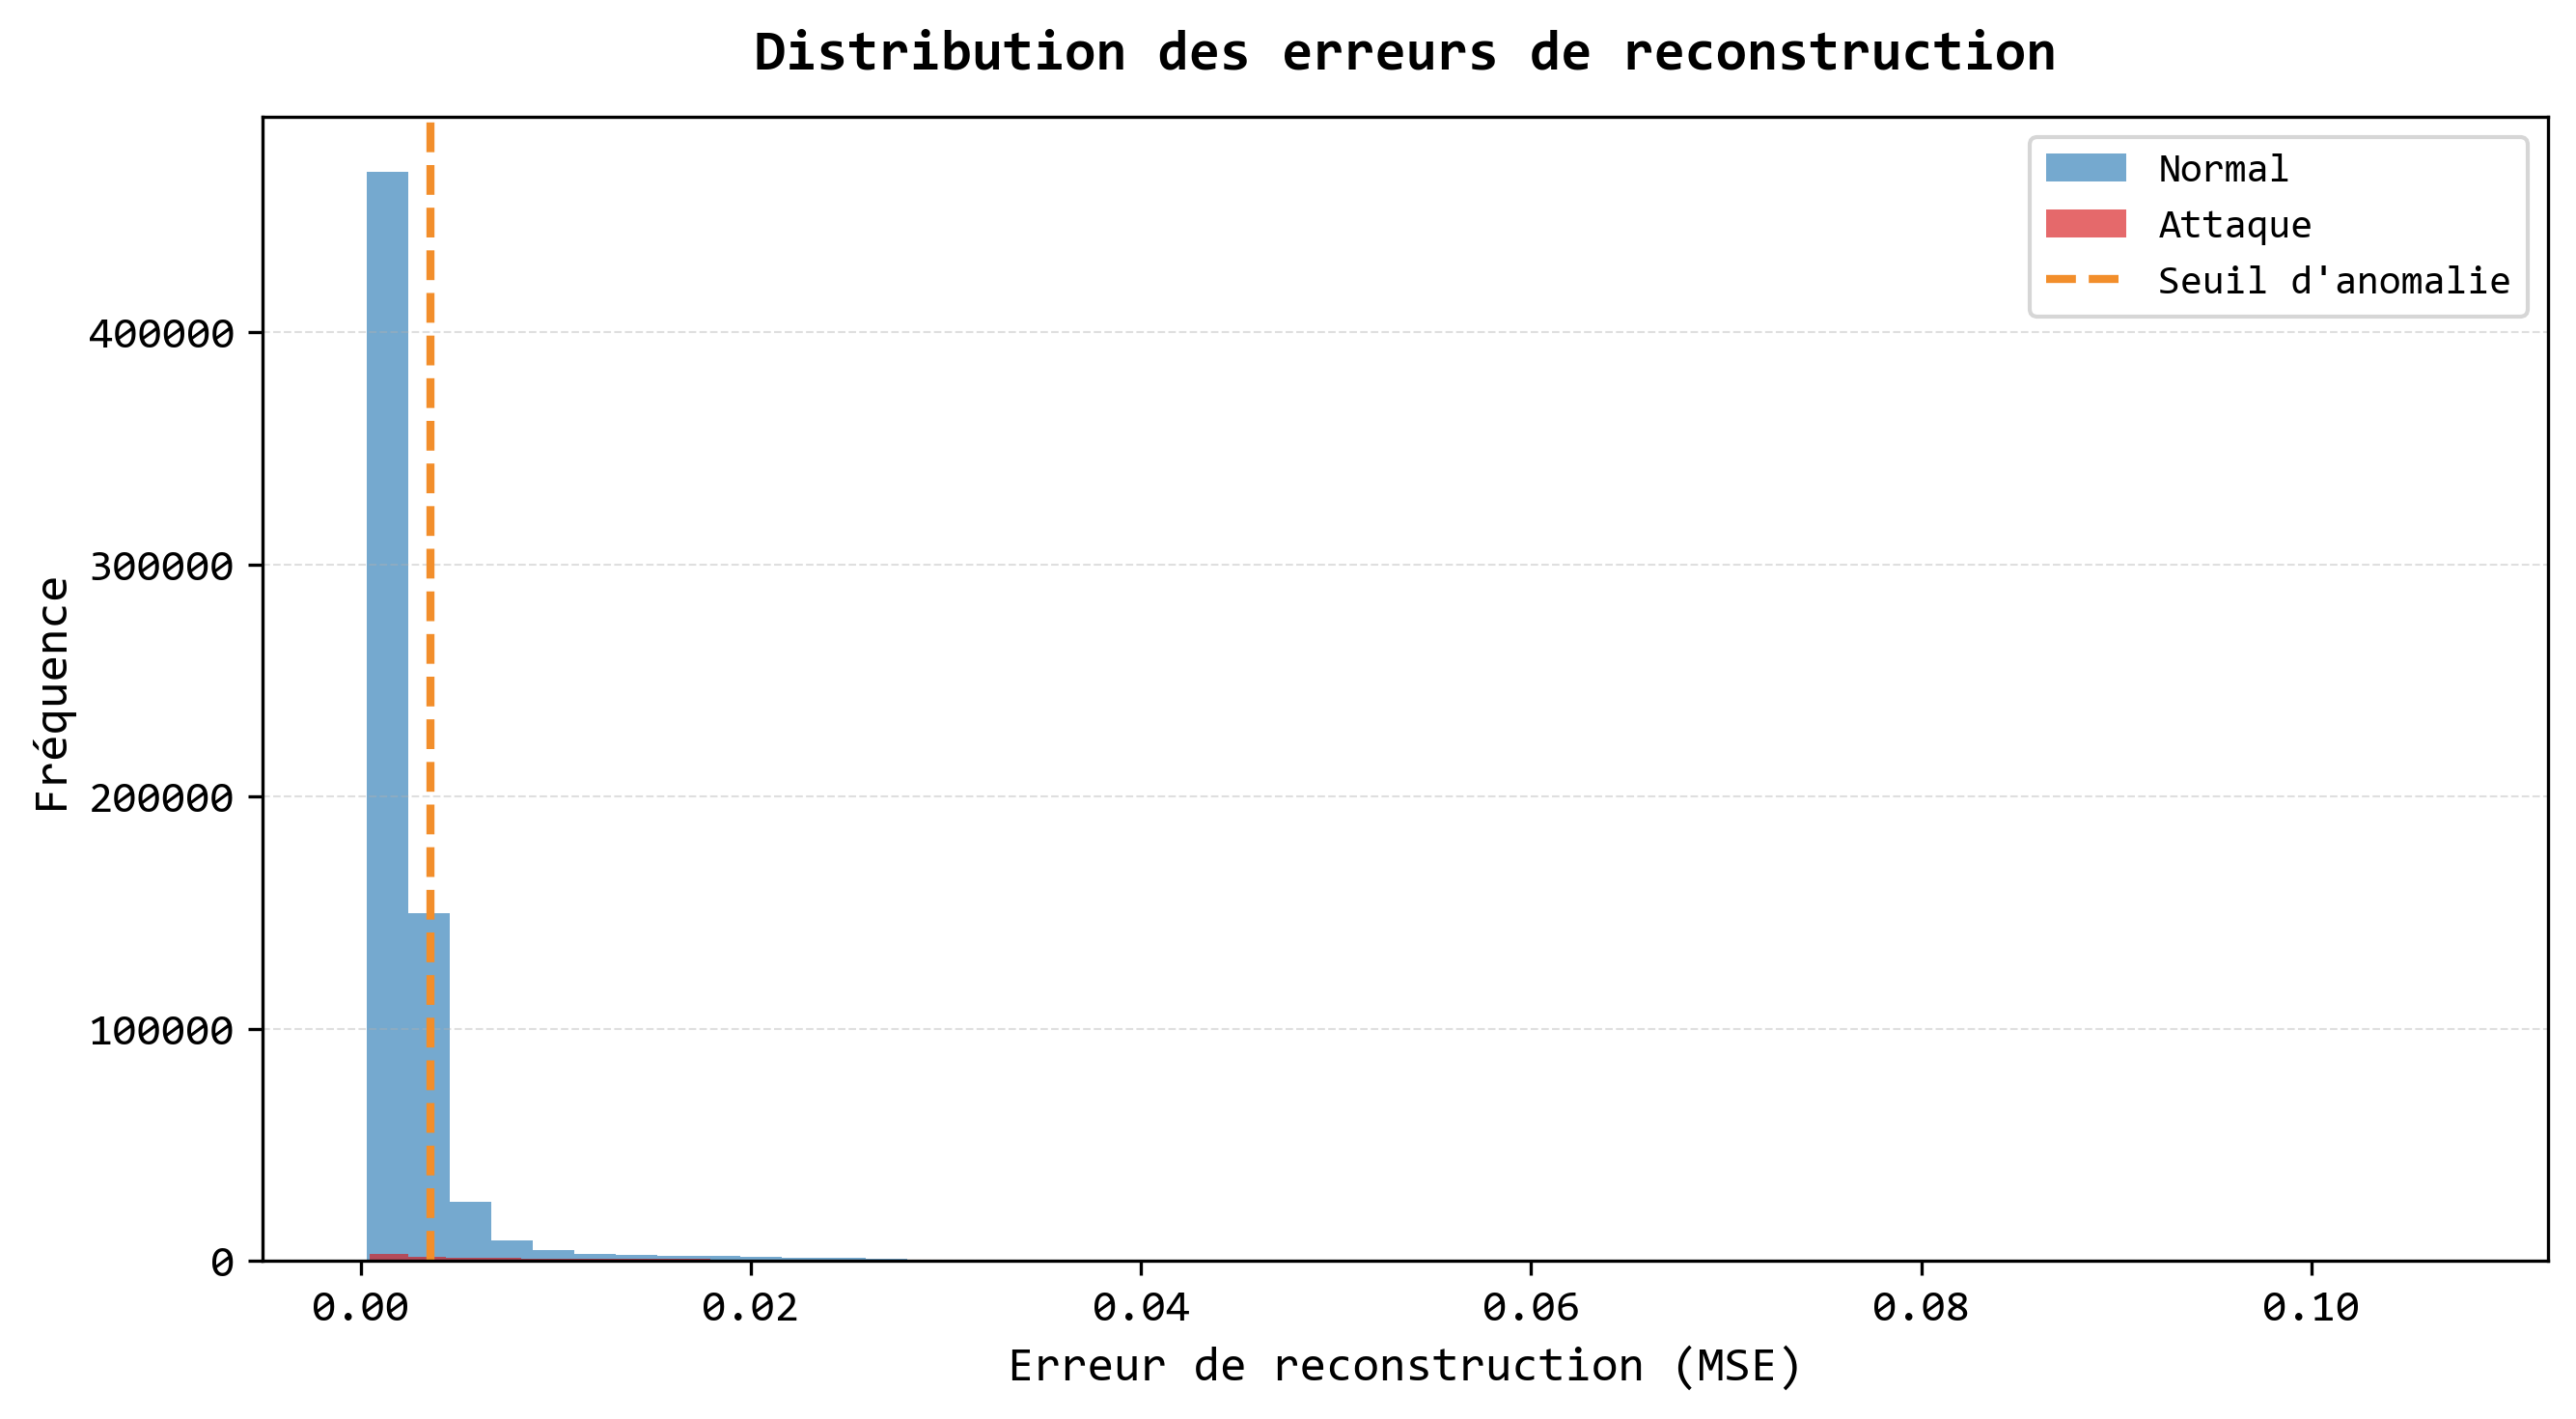

In [118]:
import os
import matplotlib.pyplot as plt


# ==========================================
# Police globale Consolas
# ==========================================

plt.rcParams["font.family"] = "Consolas"


# ==========================================
# Création du dossier de sauvegarde
# ==========================================

os.makedirs(
    "figures/evaluation",
    exist_ok=True
)


# ==========================================
# Histogramme des erreurs MSE
# ==========================================

fig, ax = plt.subplots(
    figsize=(9,5),
    dpi=300
)


# ==========================================
# Erreurs de reconstruction - Normal
# ==========================================

ax.hist(
    normal_errors,
    bins=50,
    alpha=0.65,
    color="#2C7BB6",
    label="Normal"
)


# ==========================================
# Erreurs de reconstruction - Attaque
# ==========================================

ax.hist(
    attack_errors,
    bins=50,
    alpha=0.65,
    color="#D7191C",
    label="Attaque"
)


# ==========================================
# Seuil d'anomalie
# ==========================================

ax.axvline(
    threshold,
    color="#F28E2B",
    linestyle="--",
    linewidth=2,
    label="Seuil d'anomalie"
)


# ==========================================
# Label axe X
# ==========================================

ax.set_xlabel(
    "Erreur de reconstruction (MSE)",
    fontsize=12,
    fontfamily="Consolas"
)


# ==========================================
# Label axe Y
# ==========================================

ax.set_ylabel(
    "Fréquence",
    fontsize=12,
    fontfamily="Consolas"
)


# ==========================================
# Titre
# ==========================================

ax.set_title(
    "Distribution des erreurs de reconstruction",
    fontsize=14,
    fontweight="bold",
    fontfamily="Consolas",
    pad=12
)


# ==========================================
# Légende
# ==========================================

ax.legend(
    prop={
        "family": "Consolas",
        "size": 10
    }
)


# ==========================================
# Personnalisation des graduations
# ==========================================

ax.tick_params(
    axis="both",
    labelsize=11
)


for label in ax.get_xticklabels():
    label.set_fontname("Consolas")


for label in ax.get_yticklabels():
    label.set_fontname("Consolas")


# ==========================================
# Grille
# ==========================================

ax.grid(
    axis="y",
    linestyle="--",
    linewidth=0.5,
    alpha=0.4
)


# ==========================================
# Ajustement de la figure
# ==========================================

plt.tight_layout()


# ==========================================
# Sauvegarde PNG haute résolution
# ==========================================

fig.savefig(
    "figures/evaluation/fr_lstm_error_distribution.png",
    format="png",
    dpi=300,
    bbox_inches="tight"
)


# ==========================================
# Affichage
# ==========================================

plt.show()

ROC-AUC : 0.8769


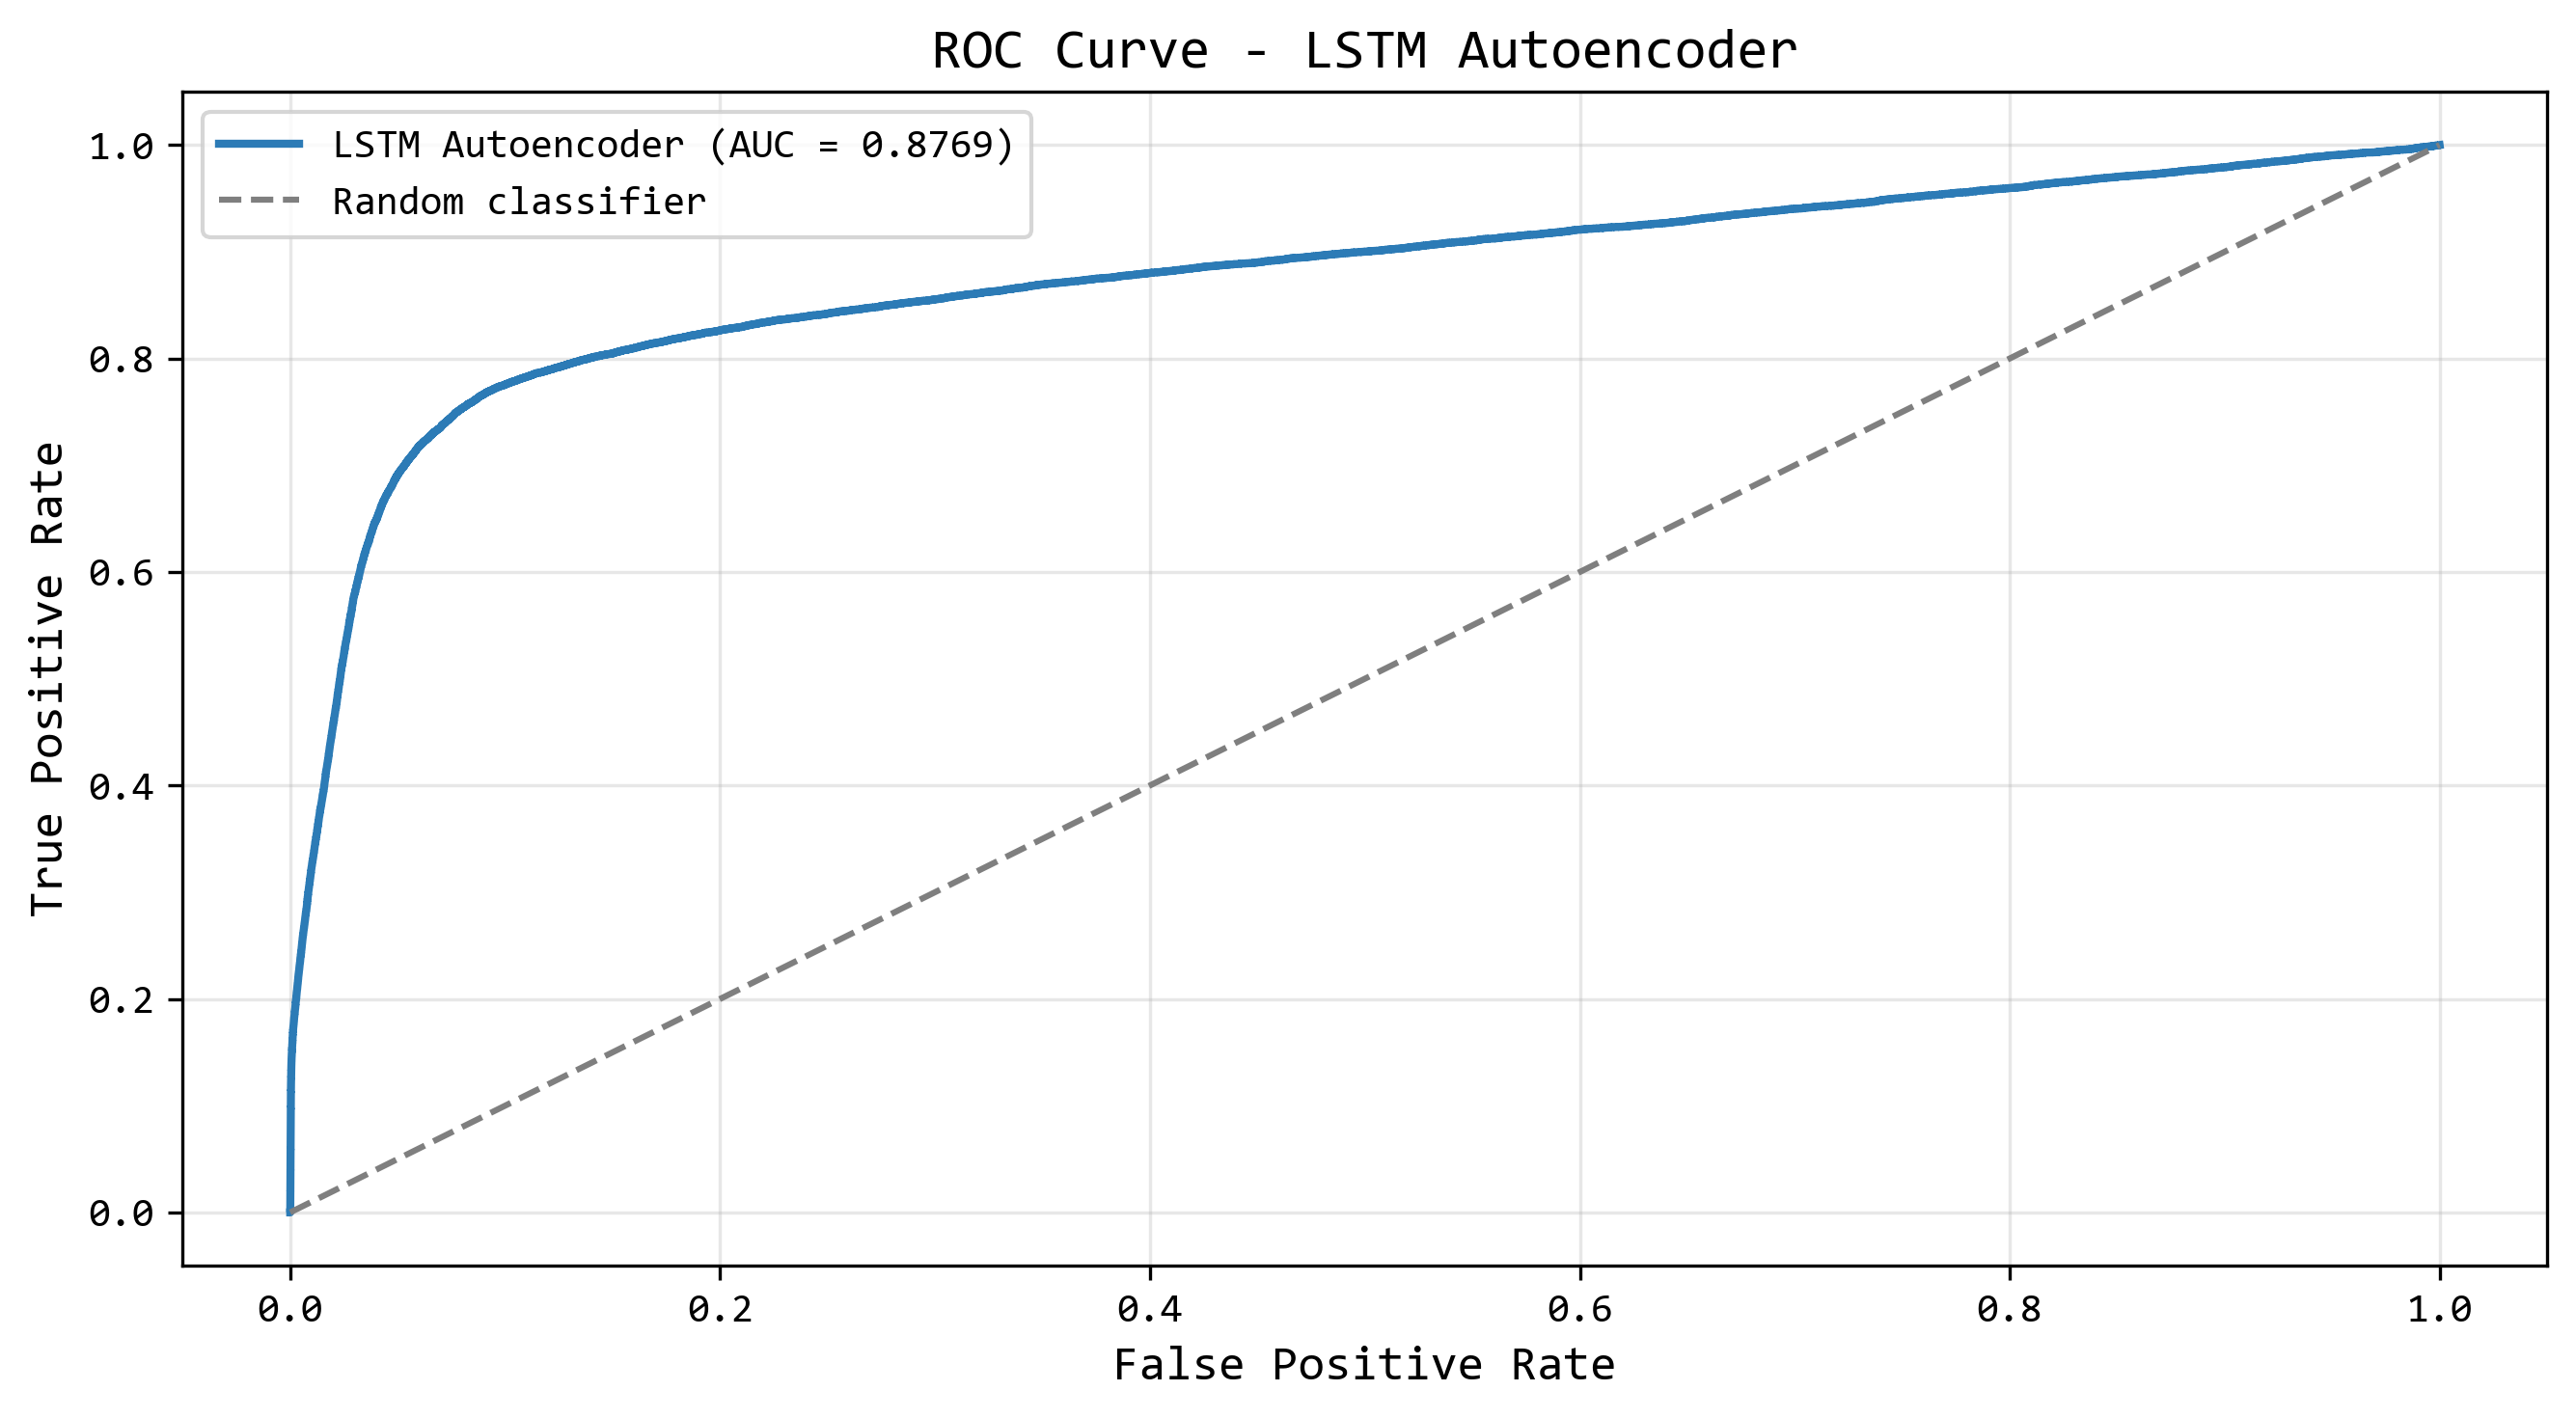

In [108]:
# ===================================
# Courbe ROC
# Cellule 15
# ===================================


# Calcul FPR et TPR

fpr, tpr, roc_thresholds = roc_curve(

    y_test_lstm,

    reconstruction_error

)



# Calcul AUC

roc_auc = auc(

    fpr,

    tpr

)



print(
    "ROC-AUC :",
    round(roc_auc, 4)
)

# ===================================
# Visualisation ROC
# ===================================


plt.rcParams["font.family"] = "Consolas"



fig, ax = plt.subplots(

    figsize=(9,5),

    dpi=300

)



# Courbe ROC

ax.plot(

    fpr,

    tpr,

    linewidth=2,

    color="#2C7BB6",

    label=f"LSTM Autoencoder (AUC = {roc_auc:.4f})"

)



# Classifieur aléatoire

ax.plot(

    [0, 1],

    [0, 1],

    linestyle="--",

    linewidth=1.5,

    color="#7F7F7F",

    label="Random classifier"

)



ax.set_xlabel(

    "False Positive Rate",

    fontsize=12,

    fontfamily="Consolas"

)



ax.set_ylabel(

    "True Positive Rate",

    fontsize=12,

    fontfamily="Consolas"

)



ax.set_title(

    "ROC Curve - LSTM Autoencoder",

    fontsize=14,

    fontfamily="Consolas"

)



ax.legend(

    prop={

        "family": "Consolas",

        "size": 10

    }

)



ax.grid(

    True,

    alpha=0.3

)

# ===================================
# Sauvegarde PNG
# ===================================


fig.savefig(

    "figures/evaluation/lstm_roc_curve.png",

    dpi=300,

    bbox_inches="tight"

)

plt.tight_layout()

Aire sous la courbe ROC (AUC) : 0.8769


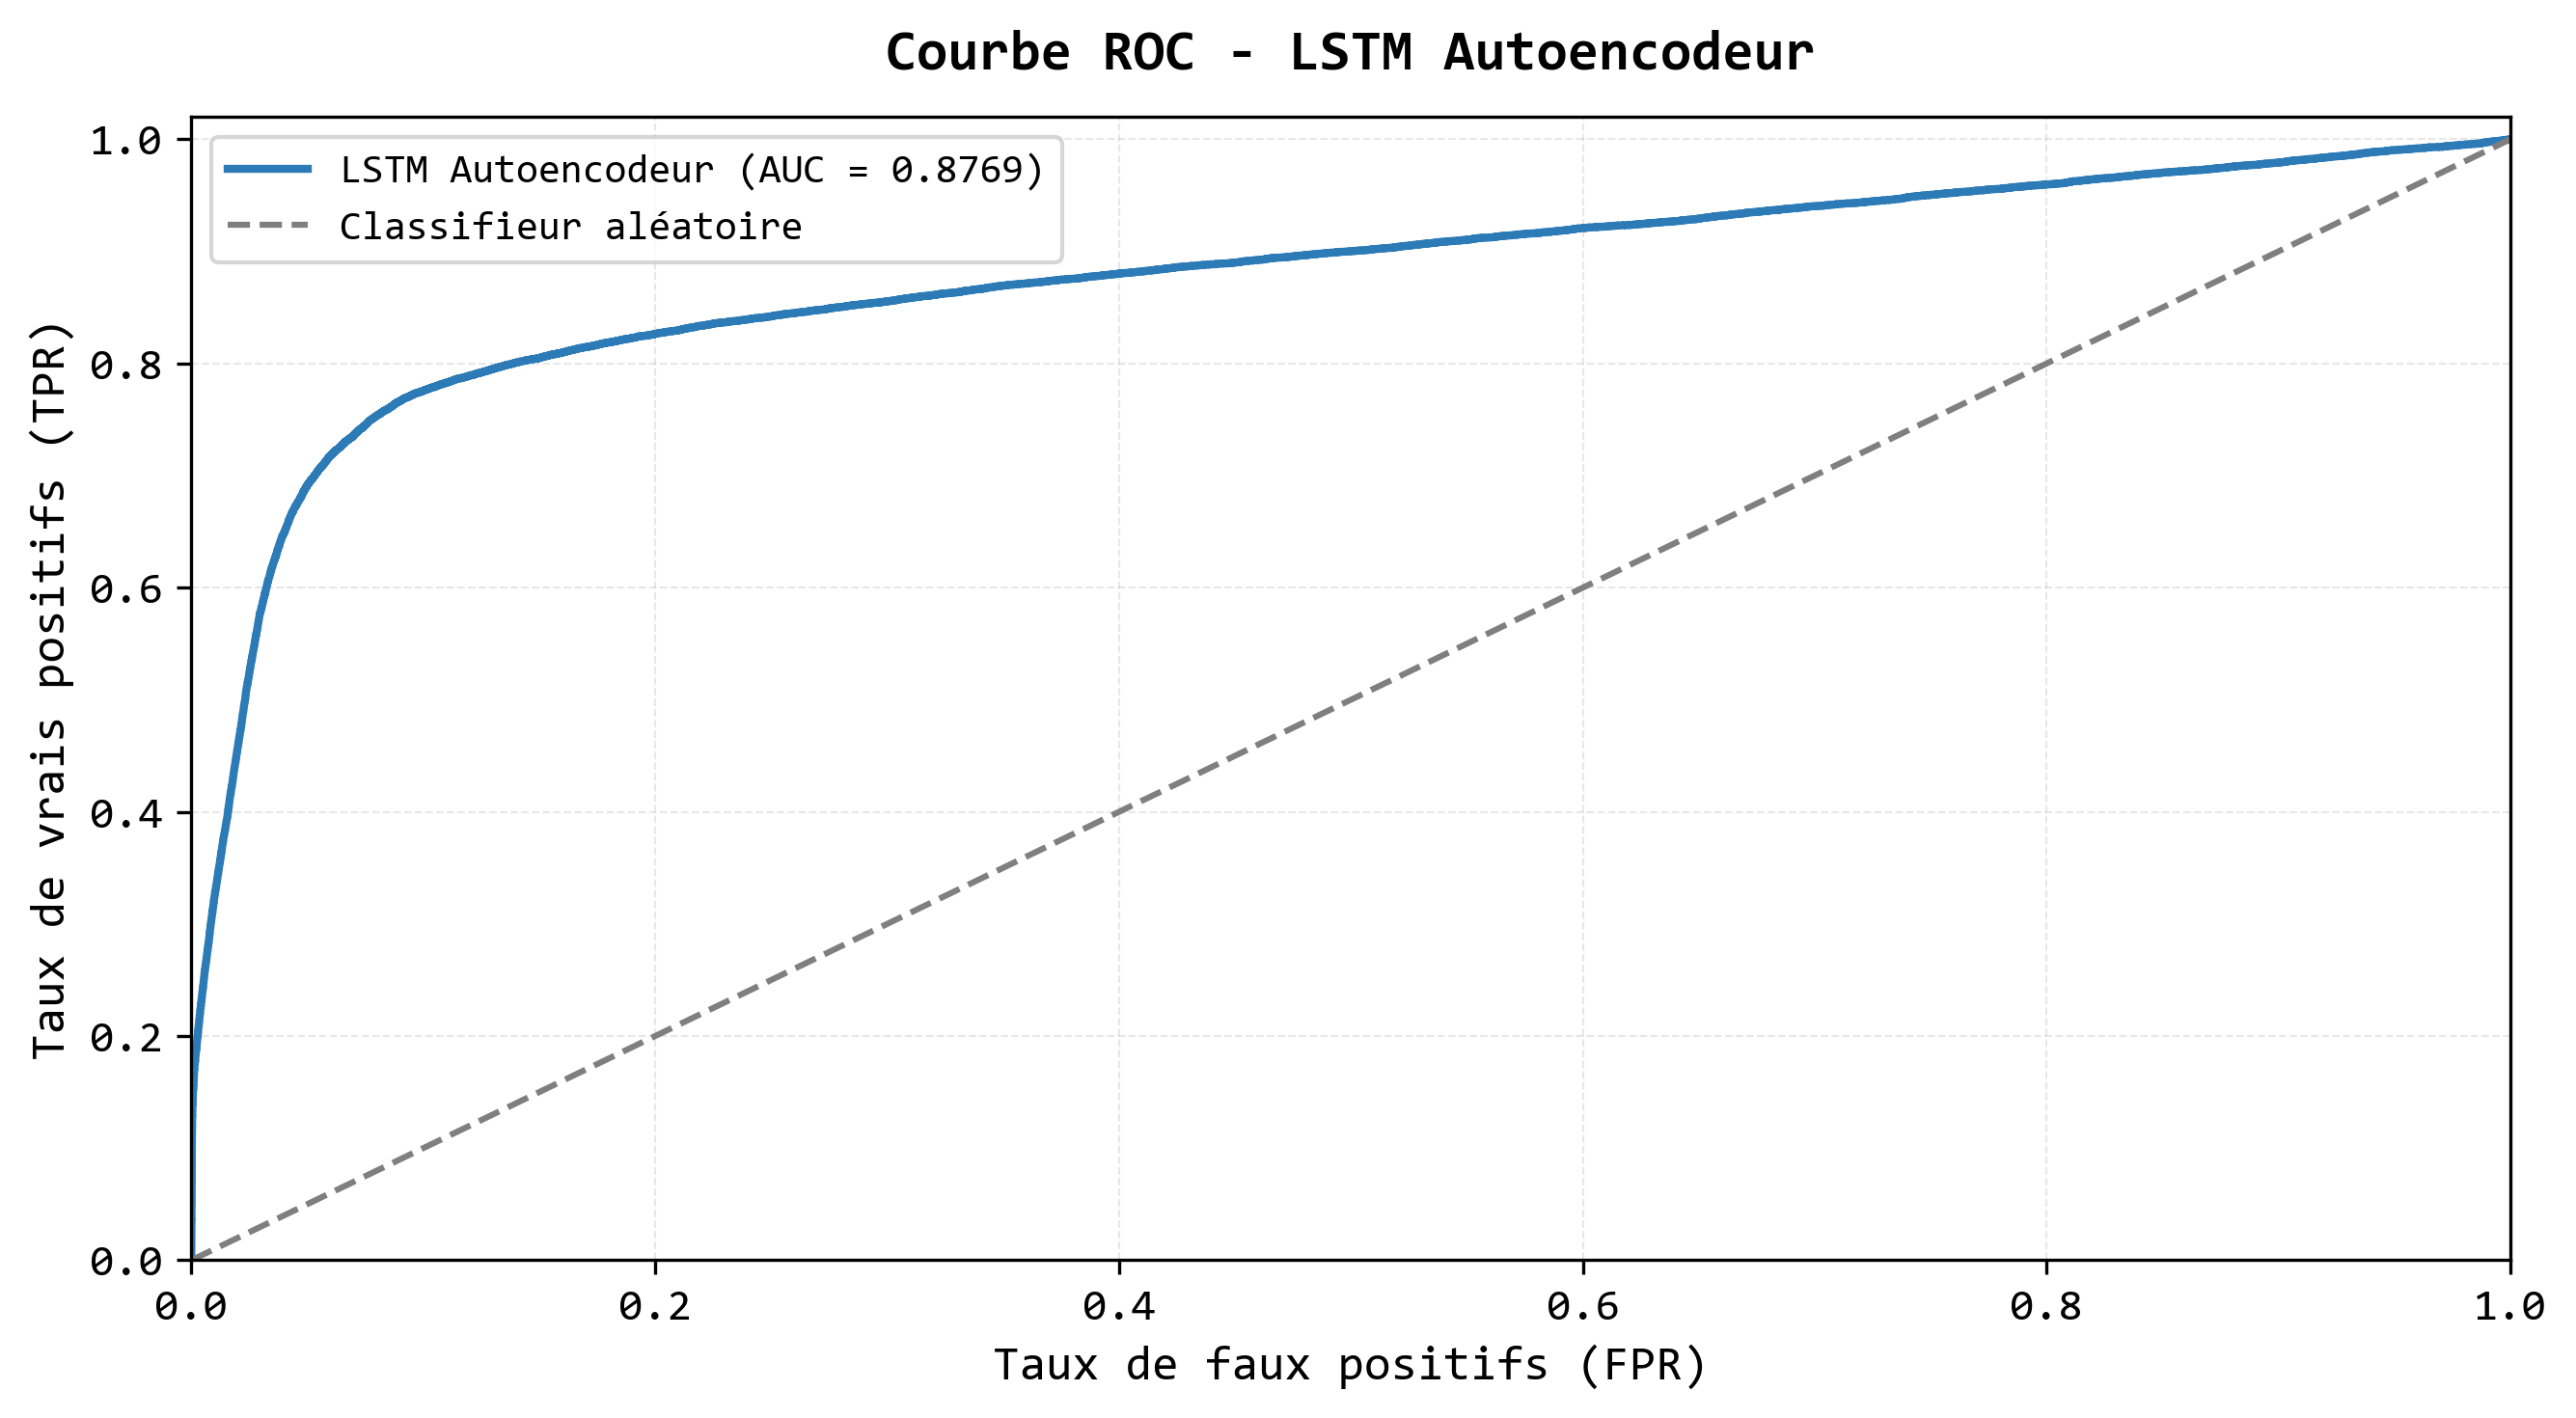

In [119]:
# ==========================================
# Courbe ROC
# ==========================================

import os
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_curve,
    auc
)


# ==========================================
# Création du dossier de sauvegarde
# ==========================================

os.makedirs(
    "figures/evaluation",
    exist_ok=True
)


# ==========================================
# Calcul du taux de faux positifs (FPR)
# et du taux de vrais positifs (TPR)
# ==========================================

fpr, tpr, roc_thresholds = roc_curve(
    y_test_lstm,
    reconstruction_error
)


# ==========================================
# Calcul de l'AUC
# ==========================================

roc_auc = auc(
    fpr,
    tpr
)


print(
    "Aire sous la courbe ROC (AUC) :",
    round(roc_auc, 4)
)


# ==========================================
# Police globale Consolas
# ==========================================

plt.rcParams["font.family"] = "Consolas"


# ==========================================
# Création de la figure
# ==========================================

fig, ax = plt.subplots(
    figsize=(9,5),
    dpi=300
)


# ==========================================
# Courbe ROC
# ==========================================

ax.plot(
    fpr,
    tpr,
    linewidth=2,
    color="#2C7BB6",
    label=f"LSTM Autoencodeur (AUC = {roc_auc:.4f})"
)


# ==========================================
# Classifieur aléatoire
# ==========================================

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    color="#7F7F7F",
    label="Classifieur aléatoire"
)


# ==========================================
# Label axe X
# ==========================================

ax.set_xlabel(
    "Taux de faux positifs (FPR)",
    fontsize=12,
    fontfamily="Consolas"
)


# ==========================================
# Label axe Y
# ==========================================

ax.set_ylabel(
    "Taux de vrais positifs (TPR)",
    fontsize=12,
    fontfamily="Consolas"
)


# ==========================================
# Titre
# ==========================================

ax.set_title(
    "Courbe ROC - LSTM Autoencodeur",
    fontsize=14,
    fontweight="bold",
    fontfamily="Consolas",
    pad=12
)


# ==========================================
# Limites des axes
# ==========================================

ax.set_xlim(
    0,
    1
)

ax.set_ylim(
    0,
    1.02
)


# ==========================================
# Légende
# ==========================================

ax.legend(
    prop={
        "family": "Consolas",
        "size": 10
    }
)


# ==========================================
# Grille
# ==========================================

ax.grid(
    True,
    linestyle="--",
    linewidth=0.5,
    alpha=0.3
)


# ==========================================
# Personnalisation des graduations
# ==========================================

ax.tick_params(
    axis="both",
    labelsize=11
)


for label in ax.get_xticklabels():
    label.set_fontname("Consolas")


for label in ax.get_yticklabels():
    label.set_fontname("Consolas")


# ==========================================
# Ajustement de la figure
# ==========================================

plt.tight_layout()


# ==========================================
# Sauvegarde PNG haute résolution
# ==========================================

fig.savefig(
    "figures/evaluation/fr_lstm_roc_curve.png",
    format="png",
    dpi=300,
    bbox_inches="tight"
)


# ==========================================
# Affichage
# ==========================================

plt.show()

In [100]:
from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)

PR-AUC : 0.4418


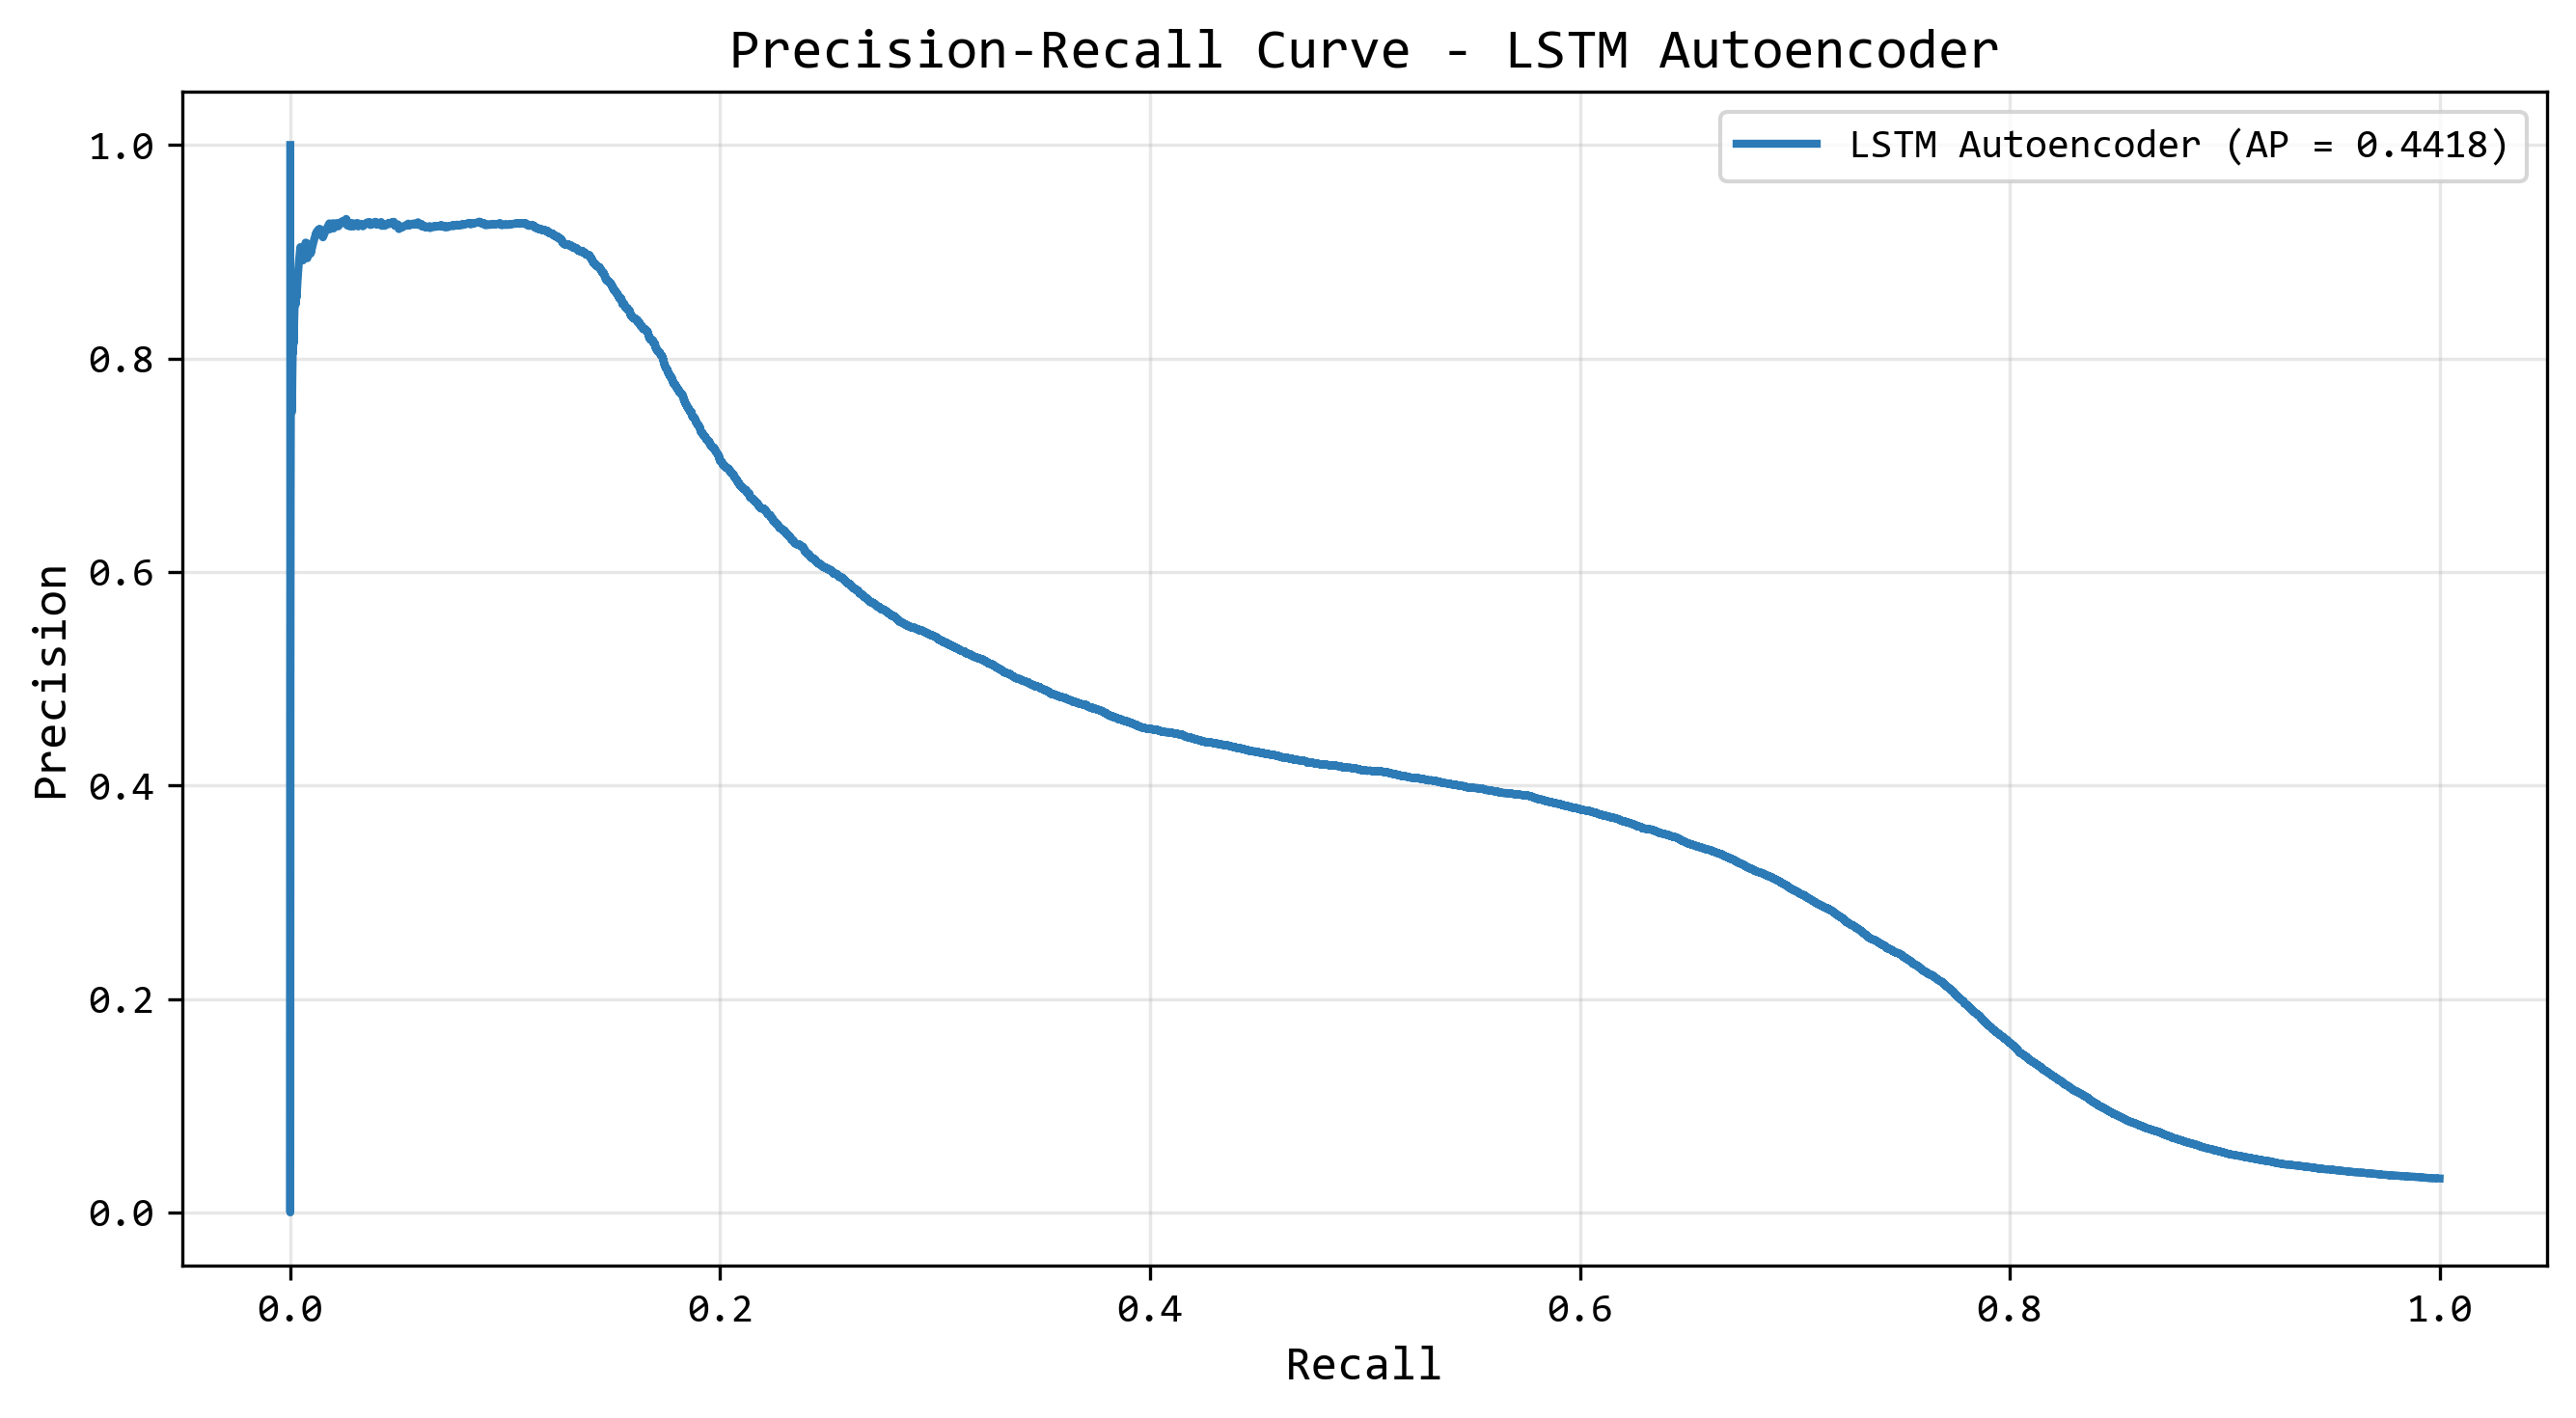

In [107]:
# ===================================
# Precision-Recall Curve
# ===================================


precision_curve, recall_curve, pr_thresholds = precision_recall_curve(

    y_test_lstm,

    reconstruction_error

)



# Calcul PR-AUC

pr_auc = average_precision_score(

    y_test_lstm,

    reconstruction_error

)



print(
    "PR-AUC :",
    round(pr_auc, 4)
)

# ===================================
# Visualisation Precision-Recall
# ===================================


plt.rcParams["font.family"] = "Consolas"



fig, ax = plt.subplots(

    figsize=(9,5),

    dpi=300

)



ax.plot(

    recall_curve,

    precision_curve,

    linewidth=2,

    color="#2C7BB6",

    label=f"LSTM Autoencoder (AP = {pr_auc:.4f})"

)



ax.set_xlabel(

    "Recall",

    fontsize=12,

    fontfamily="Consolas"

)



ax.set_ylabel(

    "Precision",

    fontsize=12,

    fontfamily="Consolas"

)



ax.set_title(

    "Precision-Recall Curve - LSTM Autoencoder",

    fontsize=14,

    fontfamily="Consolas"

)



ax.legend(

    prop={

        "family": "Consolas",

        "size": 10

    }

)



ax.grid(

    True,

    alpha=0.3

)

# ===================================
# Sauvegarde PNG
# ===================================


fig.savefig(

    "figures/evaluation/lstm_precision_recall.png",

    dpi=300,

    bbox_inches="tight"

)

plt.tight_layout()

Aire sous la courbe Précision-Rappel (PR-AUC) : 0.4418


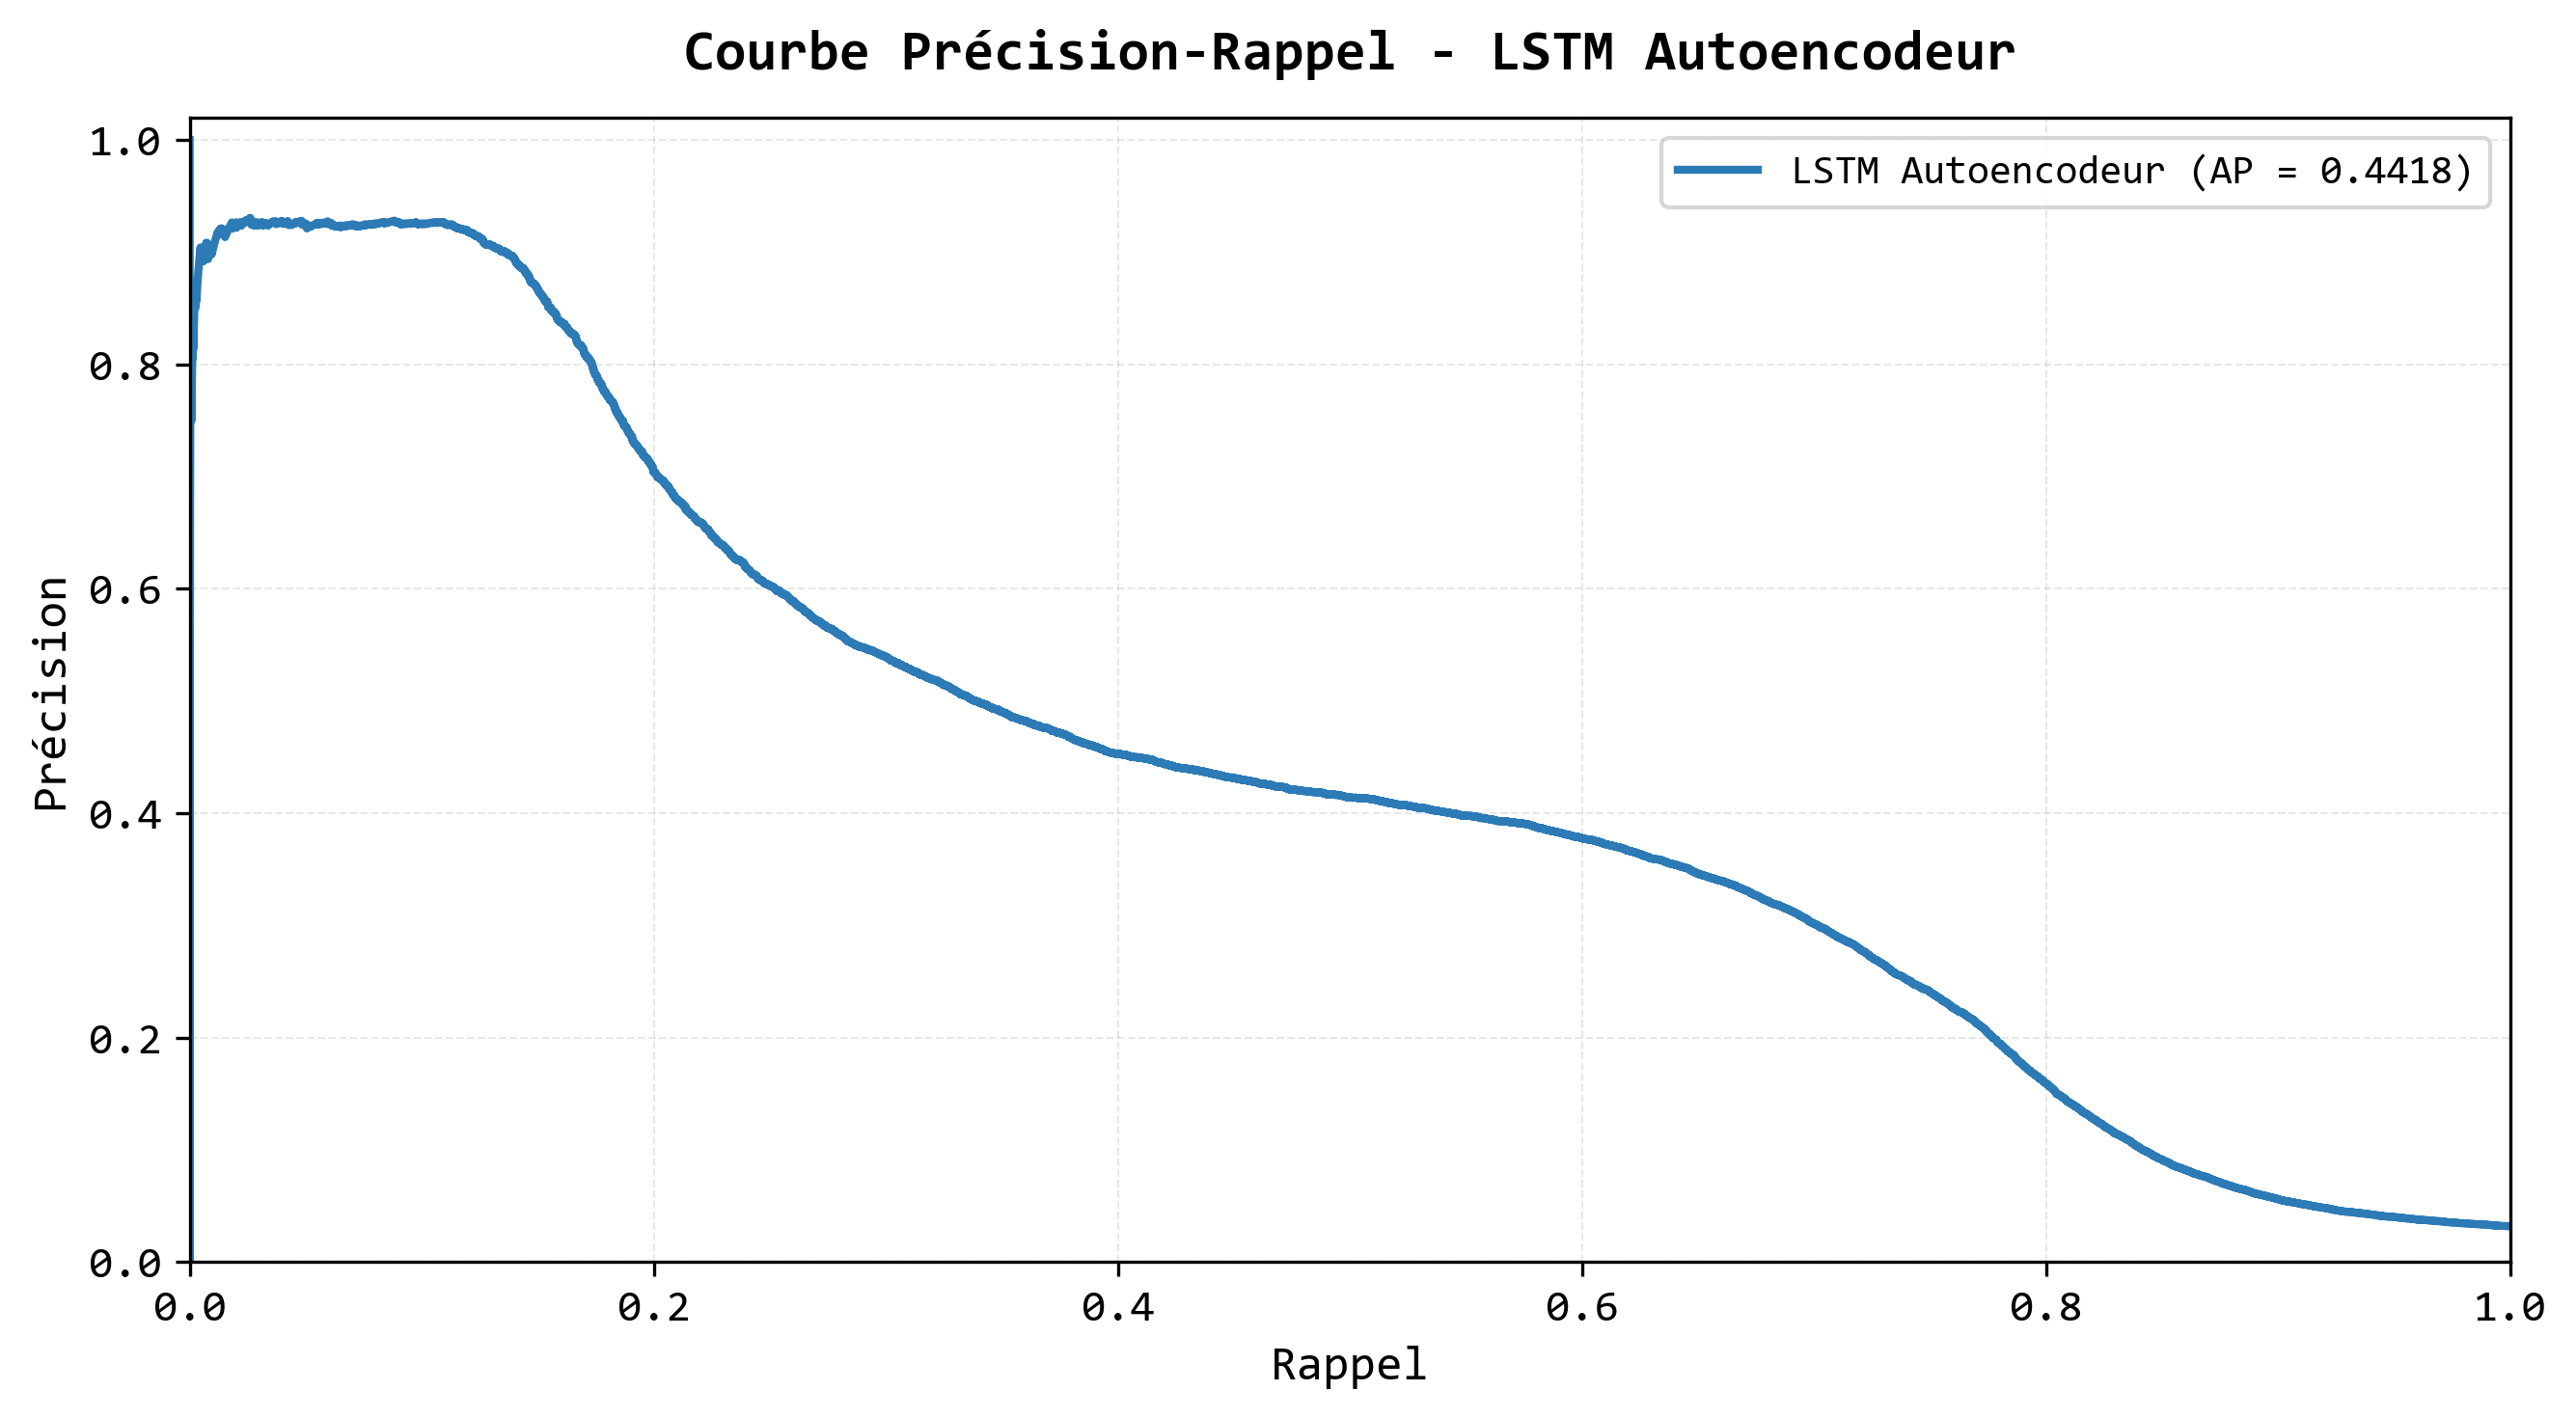

In [122]:
# ==========================================
# Courbe Précision-Rappel
# ==========================================

import os
import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)


# ==========================================
# Création du dossier de sauvegarde
# ==========================================

os.makedirs(
    "figures/evaluation",
    exist_ok=True
)


# ==========================================
# Calcul de la courbe Précision-Rappel
# ==========================================

precision_curve, recall_curve, pr_thresholds = precision_recall_curve(
    y_test_lstm,
    reconstruction_error
)


# ==========================================
# Calcul de l'aire sous la courbe
# ==========================================

pr_auc = average_precision_score(
    y_test_lstm,
    reconstruction_error
)


print(
    "Aire sous la courbe Précision-Rappel (PR-AUC) :",
    round(pr_auc, 4)
)


# ==========================================
# Police globale Consolas
# ==========================================

plt.rcParams["font.family"] = "Consolas"


# ==========================================
# Création de la figure
# ==========================================

fig, ax = plt.subplots(
    figsize=(9,5),
    dpi=300
)


# ==========================================
# Courbe Précision-Rappel
# ==========================================

ax.plot(
    recall_curve,
    precision_curve,
    linewidth=2,
    color="#2C7BB6",
    label=f"LSTM Autoencodeur (AP = {pr_auc:.4f})"
)


# ==========================================
# Labels des axes
# ==========================================

ax.set_xlabel(
    "Rappel",
    fontsize=12,
    fontfamily="Consolas"
)


ax.set_ylabel(
    "Précision",
    fontsize=12,
    fontfamily="Consolas"
)


# ==========================================
# Titre
# ==========================================

ax.set_title(
    "Courbe Précision-Rappel - LSTM Autoencodeur",
    fontsize=14,
    fontweight="bold",
    fontfamily="Consolas",
    pad=12
)


# ==========================================
# Limites des axes
# ==========================================

ax.set_xlim(
    0,
    1
)

ax.set_ylim(
    0,
    1.02
)


# ==========================================
# Légende
# ==========================================

ax.legend(
    prop={
        "family": "Consolas",
        "size": 10
    }
)


# ==========================================
# Grille
# ==========================================

ax.grid(
    True,
    linestyle="--",
    linewidth=0.5,
    alpha=0.3
)


# ==========================================
# Personnalisation des graduations
# ==========================================

ax.tick_params(
    axis="both",
    labelsize=11
)


for label in ax.get_xticklabels():
    label.set_fontname("Consolas")


for label in ax.get_yticklabels():
    label.set_fontname("Consolas")


# ==========================================
# Ajustement de la figure
# ==========================================

plt.tight_layout()


# ==========================================
# Sauvegarde PNG haute résolution
# ==========================================

fig.savefig(
    "figures/fr_evaluation_lstm_precision_recall.png",
    format="png",
    dpi=300,
    bbox_inches="tight"
)


# ==========================================
# Affichage
# ==========================================

plt.show()

In [102]:
# ===================================
# Sauvegarde PR-AUC
# ===================================


pr_results = pd.DataFrame({

    "Metric": [
        "PR-AUC"
    ],

    "Value": [
        pr_auc
    ]

})


pr_results.to_csv(

    "results/lstm_pr_auc.csv",

    index=False

)



print(
    "PR-AUC sauvegardé :",
    pr_auc
)

PR-AUC sauvegardé : 0.4418193549399426


In [103]:
# ===================================
# Sauvegarde résultats finaux
# ===================================


final_metrics.to_csv(

    "results/lstm_final_metrics.csv",

    index=False

)



print(
    "Tableau final sauvegardé"
)

Tableau final sauvegardé


In [104]:
# ===================================
# Sauvegarde du seuil
# ===================================


threshold_results = pd.DataFrame({

    "Method": [
        "95th Percentile"
    ],

    "Threshold": [
        threshold
    ]

})


threshold_results.to_csv(

    "results/lstm_threshold.csv",

    index=False

)

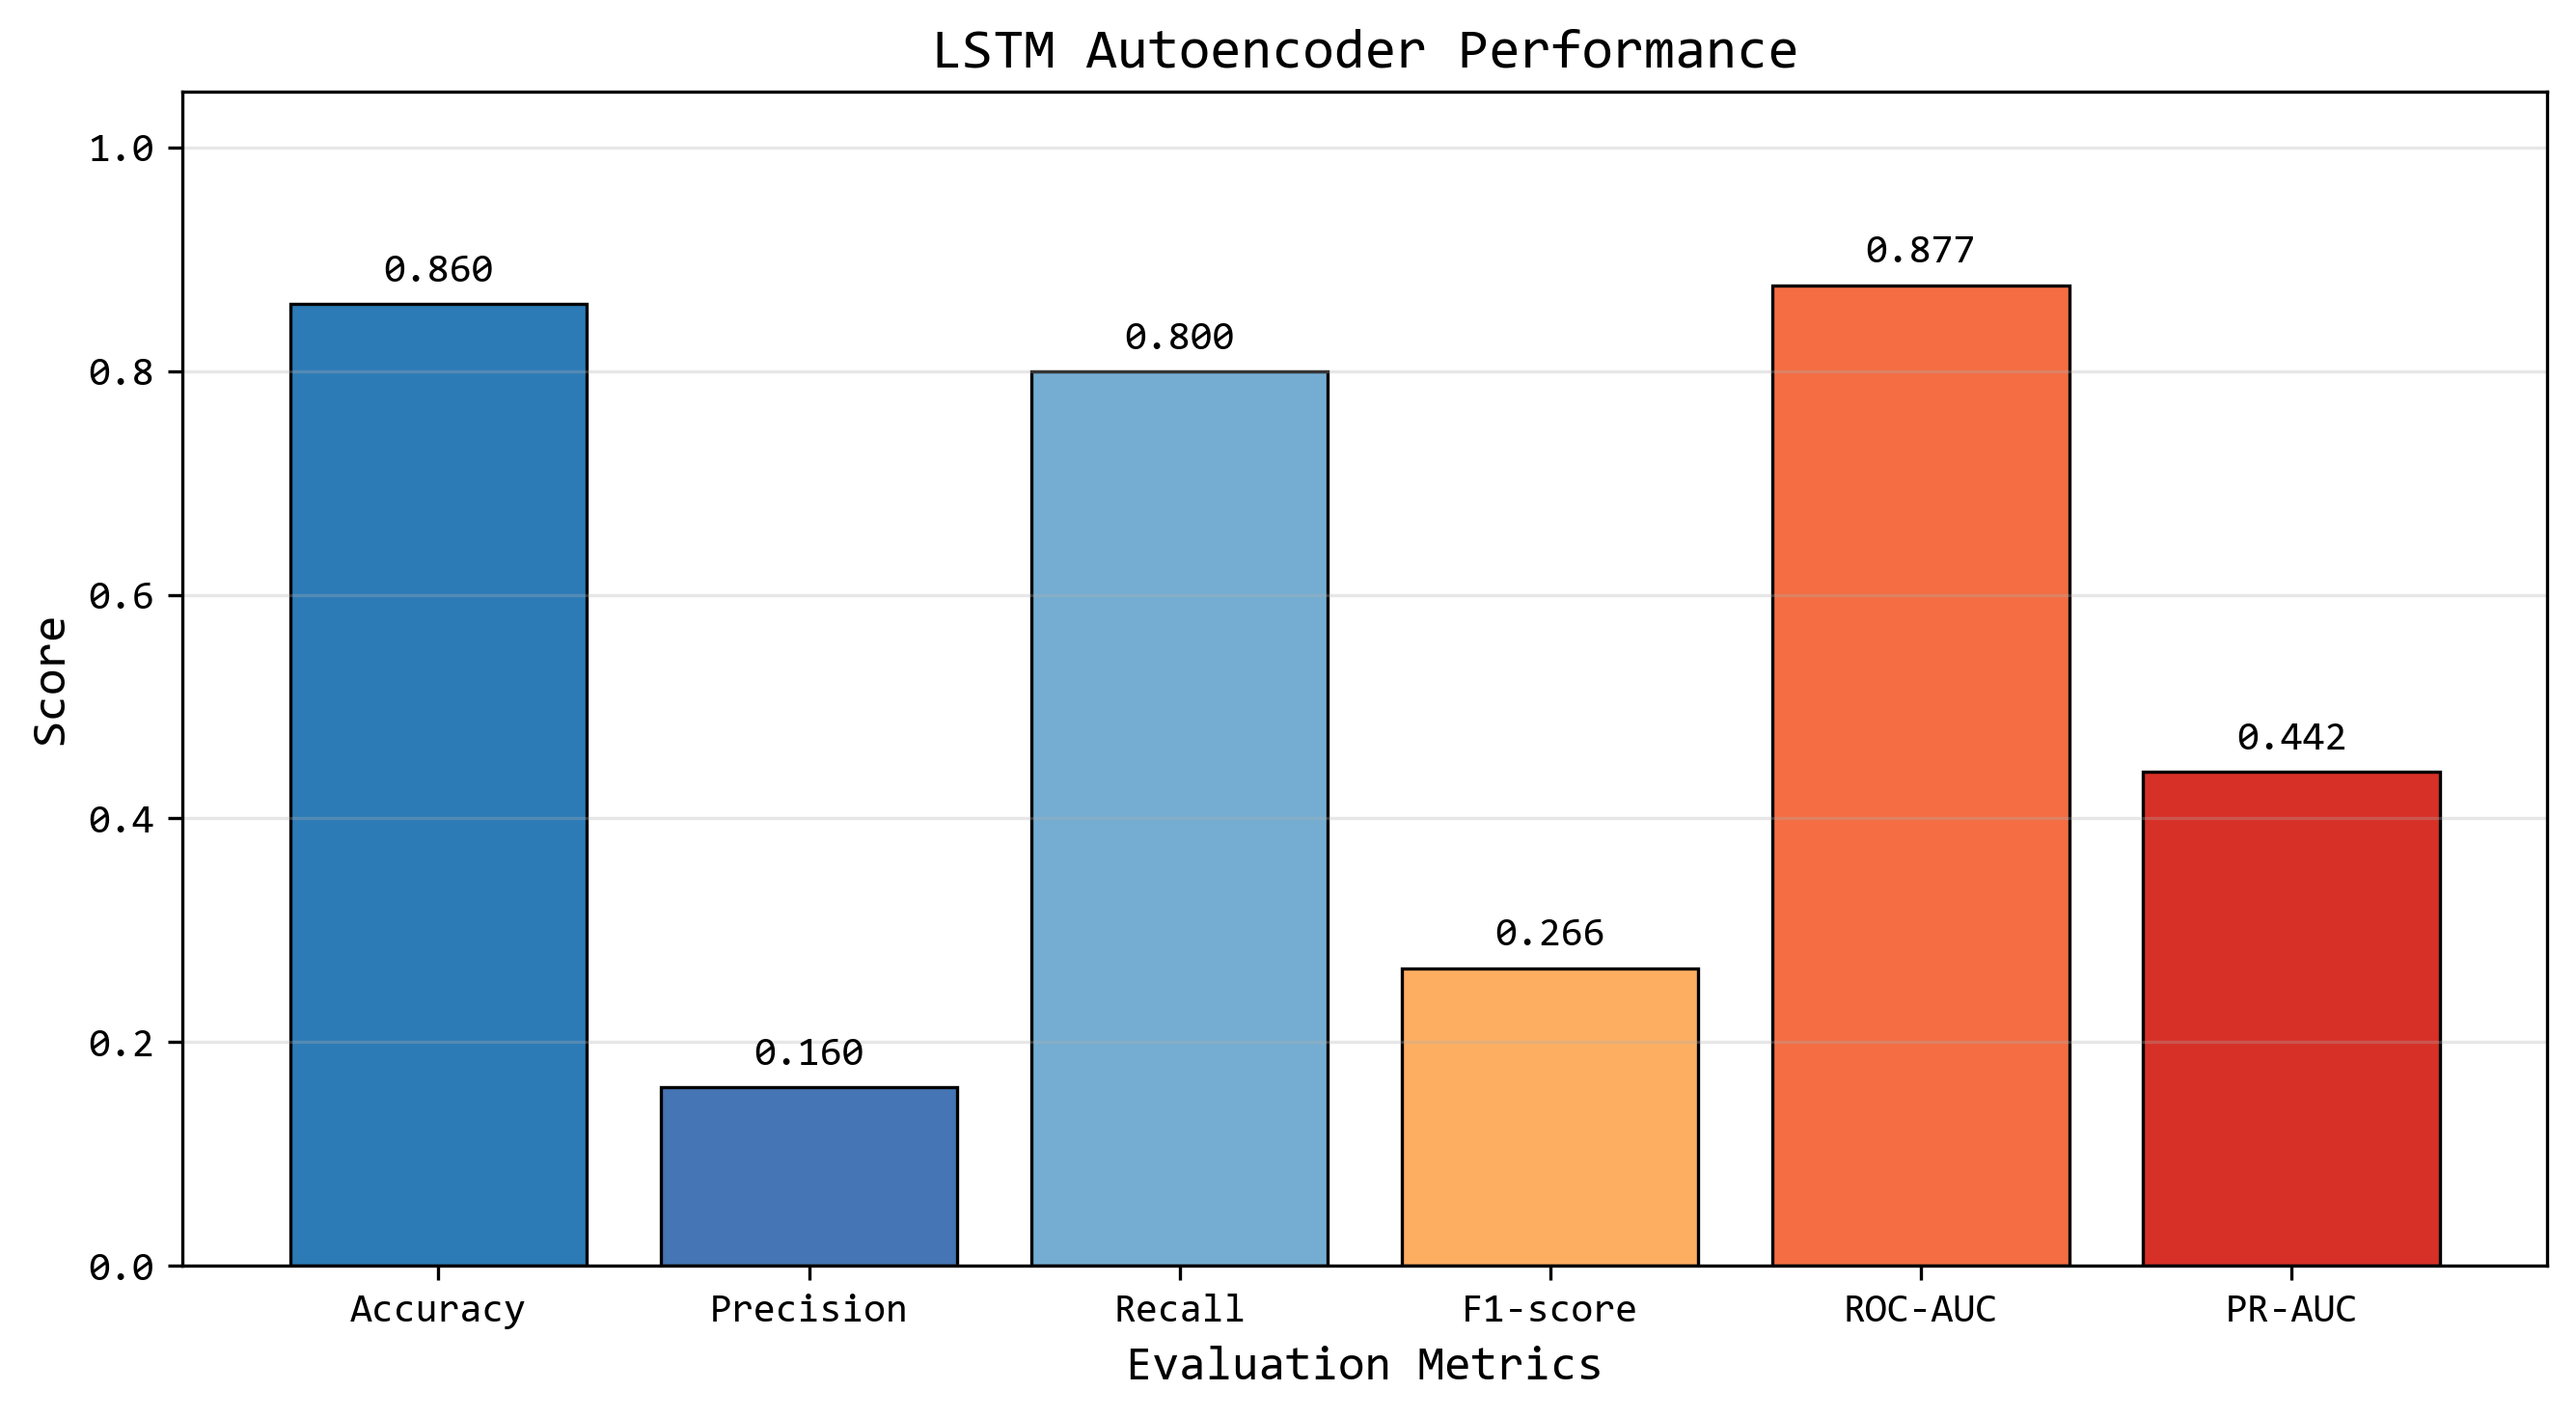

In [106]:
# ===================================
# Graphique des performances
# ===================================


plt.rcParams["font.family"] = "Consolas"



fig, ax = plt.subplots(

    figsize=(9,5),

    dpi=300

)



bars = ax.bar(

    metric_names,

    metric_values,

    color=[
        "#2C7BB6",
        "#4575B4",
        "#74ADD1",
        "#FDAE61",
        "#F46D43",
        "#D73027"
    ],

    edgecolor="black",

    linewidth=0.8

)



ax.set_ylim(

    0,

    1.05

)



ax.set_ylabel(

    "Score",

    fontsize=12,

    fontfamily="Consolas"

)



ax.set_xlabel(

    "Evaluation Metrics",

    fontsize=12,

    fontfamily="Consolas"

)



ax.set_title(

    "LSTM Autoencoder Performance",

    fontsize=14,

    fontfamily="Consolas"

)



# Valeurs au-dessus des barres

for bar, value in zip(

    bars,

    metric_values

):

    ax.text(

        bar.get_x()
        + bar.get_width() / 2,

        value + 0.02,

        f"{value:.3f}",

        ha="center",

        fontsize=10,

        fontfamily="Consolas"

    )



ax.grid(

    axis="y",

    alpha=0.3

)

# ===================================
# Sauvegarde PNG
# ===================================


fig.savefig(

    "figures/evaluation/lstm_performance_metrics.png",

    dpi=300,

    bbox_inches="tight"

)

plt.tight_layout()

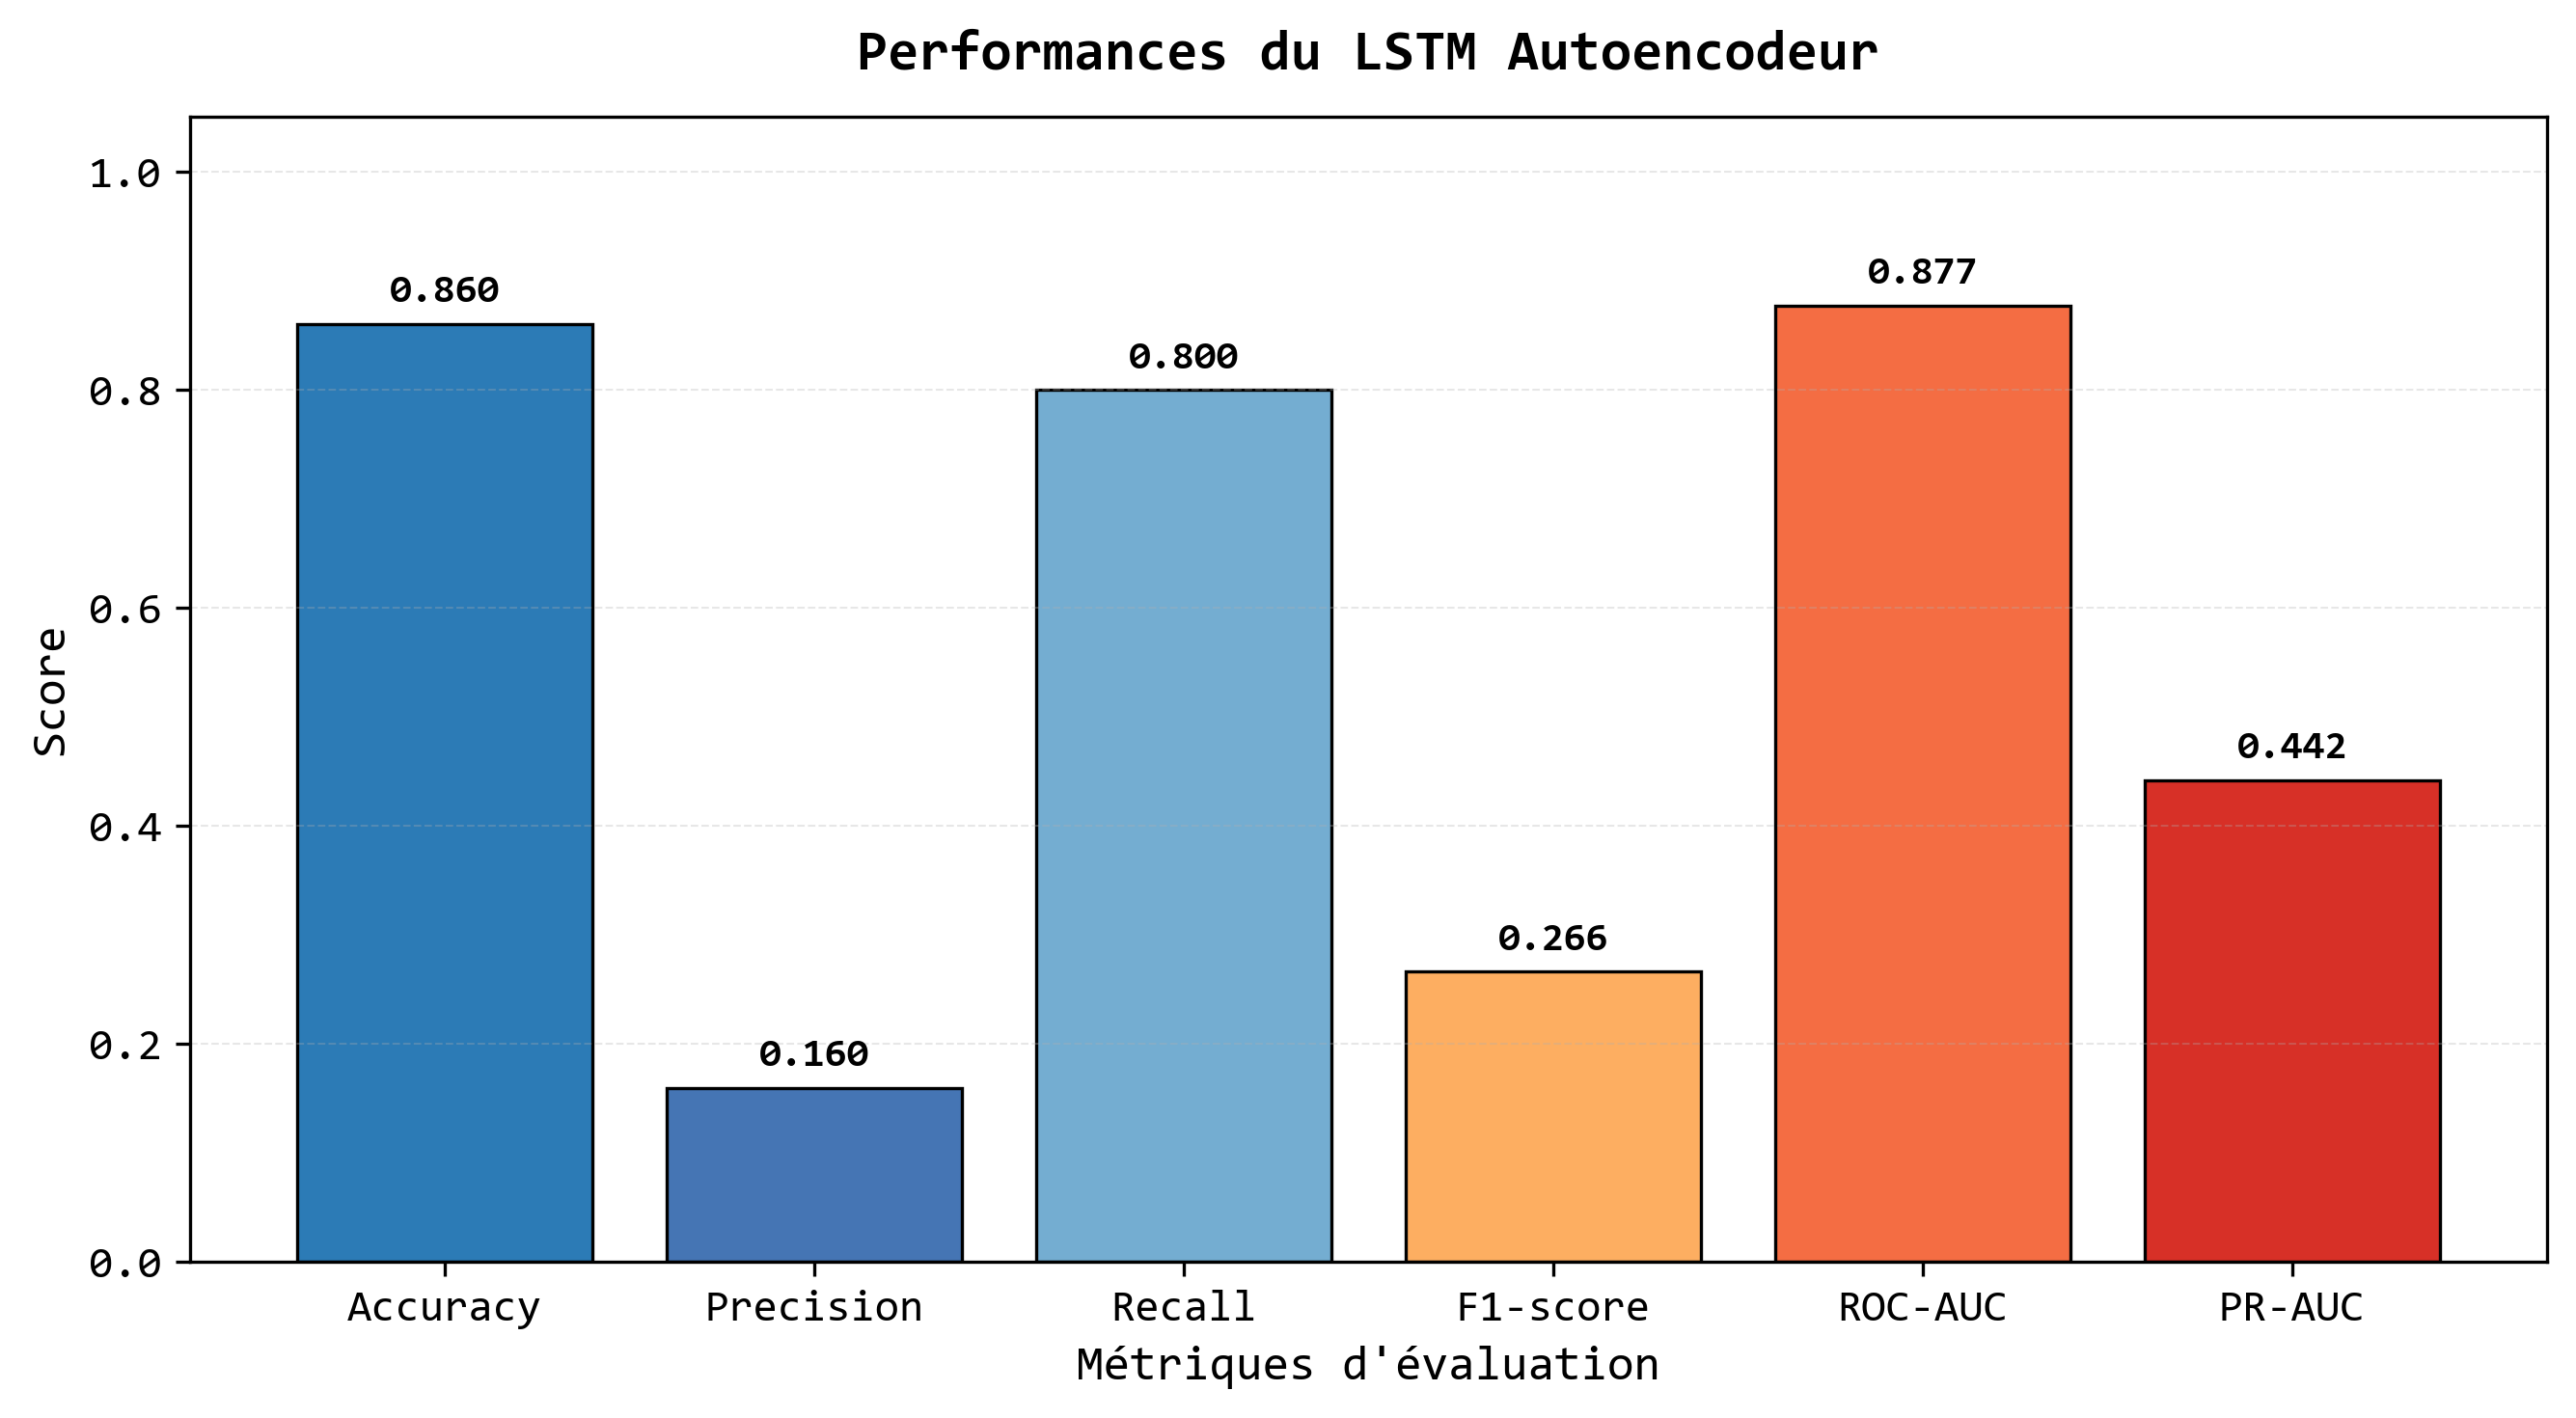

In [121]:
# ==========================================
# Graphique des performances
# ==========================================

import os
import matplotlib.pyplot as plt


# ==========================================
# Police globale Consolas
# ==========================================

plt.rcParams["font.family"] = "Consolas"


# ==========================================
# Création du dossier de sauvegarde
# ==========================================

os.makedirs(
    "figures/evaluation",
    exist_ok=True
)


# ==========================================
# Création de la figure
# ==========================================

fig, ax = plt.subplots(
    figsize=(9,5),
    dpi=300
)


# ==========================================
# Couleurs des métriques
# ==========================================

colors = [
    "#2C7BB6",
    "#4575B4",
    "#74ADD1",
    "#FDAE61",
    "#F46D43",
    "#D73027"
]


# ==========================================
# Création des barres
# ==========================================

bars = ax.bar(
    metric_names,
    metric_values,
    color=colors,
    edgecolor="black",
    linewidth=0.8
)


# ==========================================
# Limites de l'axe Y
# ==========================================

ax.set_ylim(
    0,
    1.05
)


# ==========================================
# Label axe Y
# ==========================================

ax.set_ylabel(
    "Score",
    fontsize=12,
    fontfamily="Consolas"
)


# ==========================================
# Label axe X
# ==========================================

ax.set_xlabel(
    "Métriques d'évaluation",
    fontsize=12,
    fontfamily="Consolas"
)


# ==========================================
# Titre
# ==========================================

ax.set_title(
    "Performances du LSTM Autoencodeur",
    fontsize=14,
    fontweight="bold",
    fontfamily="Consolas",
    pad=12
)


# ==========================================
# Valeurs au-dessus des barres
# ==========================================

for bar, value in zip(
    bars,
    metric_values
):

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.02,
        f"{value:.3f}",
        ha="center",
        fontsize=10,
        fontfamily="Consolas",
        fontweight="bold"
    )


# ==========================================
# Personnalisation des graduations
# ==========================================

ax.tick_params(
    axis="both",
    labelsize=11
)


for label in ax.get_xticklabels():
    label.set_fontname("Consolas")


for label in ax.get_yticklabels():
    label.set_fontname("Consolas")


# ==========================================
# Grille horizontale
# ==========================================

ax.grid(
    axis="y",
    linestyle="--",
    linewidth=0.5,
    alpha=0.3
)


# ==========================================
# Ajustement de la figure
# ==========================================

plt.tight_layout()


# ==========================================
# Sauvegarde PNG haute résolution
# ==========================================

fig.savefig(
    "figures/evaluation/fr_lstm_performance_metrics.png",
    format="png",
    dpi=300,
    bbox_inches="tight"
)


# ==========================================
# Affichage
# ==========================================

plt.show()